# Example 7.5 — Property-filtered analogue search: ibrutinib and BTK

A reproducible record of an AI-assisted BindingDB analysis: each prompt, the BindingDB tool calls that answered it with their recorded results, the answer, and its figures. Run all cells to show the recorded results, or rerun every call on your own copy of the database and check each result against the recorded one.

- **Date:** 2026-11-23
- **Model:** claude-sonnet-5-5
- **Data:** BindingDB release **202611** (`BDB-mySQL_All_202611_dmp.zip`, SHA-256 `daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381`)
- **Database build:** 2026-11-21T01:08:15+00:00, DuckDB 1.5.6
- **Derived data:** standard InChIKeys computed from SMILES by RDKit 2026.03.6; compound_property computed from SMILES (largest fragment) by RDKit 2026.03.6
- **Server:** mcp-bindingdb v0.1.17, commit [`79dae5d22c0f`](https://github.com/sbl-sdsc/mcp-bindingdb/commit/79dae5d22c0f15b8ded9b49adc8b105f0463703a)
- **Software:** python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5
- **Notebook generated:** 2026-11-24T04:56:28Z
- **Contents:** 1 exchange · 8 tool calls · 1 figure

### How to run

Keep the notebook in its folder, which holds everything it needs: `requirements.txt` (mcp-bindingdb at its commit and the versions of the packages it needs), the recorded results in `data/` and the figures in `figures/`. With [uv](https://docs.astral.sh/uv/), from that folder (replace the path with yours):

```bash
cd /path/to/7.5-property-filtered-analogues-notebook
uv run --no-project --with-requirements requirements.txt --with jupyterlab jupyter lab 7.5-property-filtered-analogues-notebook.ipynb
```

then choose Run → Run All Cells. The first start installs the packages, which takes a minute or two; the cells show the recorded results, so no database is needed. Without uv: `pip install -r requirements.txt jupyterlab`, then `jupyter lab 7.5-property-filtered-analogues-notebook.ipynb` in the folder.

### How to rerun the calls

To rerun every BindingDB call on your own copy of release 202611 and check each result against the recorded one, set `RERUN = True` in the setup cell and run all cells, or rerun the notebook without opening Jupyter, writing a copy with the new results:

```bash
cd /path/to/7.5-property-filtered-analogues-notebook
BINDINGDB_RERUN=1 uv run --no-project --with-requirements requirements.txt --with nbconvert jupyter nbconvert --to notebook --execute --output 7.5-property-filtered-analogues-notebook-rerun.ipynb 7.5-property-filtered-analogues-notebook.ipynb
```

A rerun needs the database: the one `BINDINGDB_DUCKDB=/path/to/bindingdb_202611.duckdb` names (put it before `uv run`), else the newest one mcp-bindingdb built on this computer, for example for Claude Desktop. With neither, the first rerun builds one, which takes about half an hour and 2.4 GB. To build exactly release 202611, with a clone of mcp-bindingdb:

```bash
git clone https://github.com/sbl-sdsc/mcp-bindingdb.git
cd mcp-bindingdb
git checkout 79dae5d22c0f15b8ded9b49adc8b105f0463703a
scripts/build_duckdb.sh --release 202611
```

The setup cell checks the database's release and source checksum against the recorded ones.

Run as it is, each call cell shows its recorded result, read from `data/` and checked against the SHA-256 digest recorded in the cell. Rerun, it shows the new result with ✅ when it matches the recorded one (floats to 10 significant digits, ids of viewers and files left out). Calls to PubChem, RCSB or PDBe depend on those services and may differ. The prose answers are the model's and are not recomputed.

In [ ]:
# Shows the results recorded during the session (data/), so the notebook runs without a database. Set
# RERUN = True (or start Jupyter with BINDINGDB_RERUN=1) to rerun every BindingDB call on a local copy of
# the database instead and check it against its recorded result: see 'How to rerun the calls' above.
from mcp_bindingdb.notebook import Replay

RERUN = False
replay = Replay(release='202611', source_zip_sha256='daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381', rerun=RERUN)

Recorded with BindingDB release 202611, mcp-bindingdb v0.1.17 (commit 79dae5d22c0f)
python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5


## Exchange 1

**👤 User**

I want analogues of ibrutinib that are potent on BTK but smaller and free of problem groups. Search by similarity with property filters and show me what survives.

In [ ]:
# Call 1 · search_compounds · ran 2026-11-24 04:56:19 UTC
await replay.call(1, 'search_compounds', {'query': 'ibrutinib', 'limit': 5},
                  sha256='f3a86715afc5f84f867501df709654cf89804e255da749df4d57d71785710c80')

**Call 1** · `search_compounds` · recorded result · sha256 `f3a86715afc5…`

_1 row_

| monomerid | bdbm_id | name | inchi_key | smiles | mol_weight | n_activities | n_targets | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 50357312 | BDBM50357312 | IBRUTINIB | XYFPWWZEPKGCCK-GOSISDBHSA-N | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C | 440.2 | 454 | 49 | IBRUTINIB |


In [ ]:
# Call 2 · search_targets · ran 2026-11-24 04:56:19 UTC
await replay.call(2, 'search_targets', {'query': 'BTK', 'limit': 5},
                  sha256='fbca96d971f2e5ecaaaf2d9122b5bfd14c7910be8c6eb88c918e6f8f2351d7a2')

**Call 2** · `search_targets` · recorded result · sha256 `fbca96d971f2…`

_5 rows, truncated at the limit_

| target_kind | target_id | name | uniprot | uniprot_raw | organism | type | n_activities | n_compounds | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 1846 | Tyrosine-protein kinase BTK | Q06187 | Q06187 | Homo sapiens | Enzyme | 23124 | 13927 | BTK |
| polymer | 502 | Tyrosine-protein kinase BTK \[C481S\] | Q06187 | Q06187\[C481S\] | Homo sapiens | Enzyme Catalytic Domain | 1018 | 854 | BTK |
| polymer | 934 | Tyrosine-protein kinase BTK \[386-659\] | Q06187 | Q06187\[386-659\] | Homo sapiens | Enzyme Catalytic Domain | 937 | 789 | BTK |
| polymer | 479 | Tyrosine-protein kinase BTK \[393-659\] | Q06187 | Q06187\[393-659\] | Homo sapiens | Enzyme Catalytic Domain | 358 | 354 | BTK |
| polymer | 1098 | Tyrosine-protein kinase BTK \[328-659\] | Q06187 | Q06187\[328-659\] | Homo sapiens | Enzyme Catalytic Domain | 122 | 121 | BTK |


In [ ]:
# Call 3 · get_compound · ran 2026-11-24 04:56:19 UTC
await replay.call(3, 'get_compound', {'monomerid': 50357312},
                  sha256='b8aa998637d819d70e020a8dbd261dee5272d518ff2365491ddf22d6c45c4ee4')

**Call 3** · `get_compound` · recorded result · sha256 `b8aa998637d8…`

| name | smiles |
| --- | --- |
| IBRUTINIB | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C |

```json
{
  "compound": {
    "monomerid": 50357312,
    "bdbm_id": "BDBM50357312",
    "name": "IBRUTINIB",
    "inchi_key": "XYFPWWZEPKGCCK-GOSISDBHSA-N",
    "smiles": "Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)[C@@H]1CCCN(C1)C(=O)C=C",
    "formula": "C25H24N6O2",
    "mol_weight": 440.2,
    "type": "Small organic molecule",
    "het_pdb": "",
    "n_pdb_ids_exact": 0,
    "n_activities": 454,
    "n_targets": 49,
    "inchi": "InChI=1S/C25H24N6O2/c1-2-21(32)30-14-6-7-18(15-30)31-25-22(24(26)27-16-28-25)23(29-31)17-10-12-20(13-11-17)33-19-8-4-3-5-9-19/h2-5,8-13,16,18H,1,6-7,14-15H2,(H2,26,27,28)/t18-/m1/s1",
    "pdb_ids_exact": "",
    "pdb_ids_sub": null
  },
  "synonyms": [
    "IBRUTINIB",
    "PCI-32765",
    "US9181263, 1",
    "US9278100, 1",
    "US9108973, Ref 1",
    "US10919899, Ibrutinib",
    "US20240358707, Compound 13",
    "US10835536, Ref. Ex. Comp 1",
    "US10793575, Example ibrutinib",
    "US11078206, Example Ibrutinib",
    "US11186578, Example Ibrutinib",
    "US11339167, Example Ibrutinib",
    "US11407754, Example Ibrutinib",
    "US10711006, Compound Ibrutinib",
    "US12606566, Compound Ibrutinib",
    "US10124003, Ref. Ex. Compound 1",
    "US20230364079, Example Ibrutinib",
    "US20240059694, Compound Ibrutinib",
    "US20240139326, Compound Ibrutinib",
    "US20250304585, Compound Ibrutinib"
  ],
  "properties": {
    "heavy_atoms": 33,
    "mw": 440.51,
    "clogp": 4.22,
    "tpsa": 99.16,
    "hbd": 2,
    "hba": 8,
    "rotatable_bonds": 5,
    "rings": 5,
    "aromatic_rings": 4,
    "fsp3": 0.2,
    "qed": 0.467,
    "ro5_violations": 0,
    "scaffold": "c1ccc(Oc2ccc(-c3nn([C@@H]4CCCNC4)c4ncncc34)cc2)cc1",
    "generic_scaffold": "C1CCC(CC2CCC(C3CC(C4CCCCC4)C4CCCCC34)CC2)CC1",
    "pains": [],
    "brenk": [
      "Michael_acceptor_1"
    ],
    "nih": [
      "acrylate",
      "halo_acrylate"
    ]
  }
}
```

**top_targets**: 25 rows

| polymerid | complexid | target_name | uniprot_raw | organism | n_measurements | best_p_affinity | affinity_types | best_ligand_efficiency |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 150 | 10.1 | EC50, IC50, Kd, Ki | 0.42 |
| 5620 |  | Tyrosine-protein kinase Blk | P51451 | Homo sapiens | 17 | 10 | EC50, IC50, Kd | 0.42 |
| 5143 |  | Receptor tyrosine-protein kinase erbB-4 | Q15303 | Homo sapiens | 15 | 10 | IC50, Kd | 0.42 |
| 2712 |  | Cytoplasmic tyrosine-protein kinase BMX | P51813 | Homo sapiens | 20 | 9.4 | IC50, Kd | 0.39 |
| 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens | 48 | 9.3 | EC50, IC50, Kd | 0.39 |
| 5624 |  | Tyrosine-protein kinase Tec | P42680 | Homo sapiens | 18 | 9.3 | IC50, Kd | 0.39 |
| 8772 |  | Tyrosine-protein kinase TXK | P42681 | Homo sapiens | 8 | 9.21 | IC50, Kd | 0.38 |
| 188 |  | Receptor tyrosine-protein kinase erbB-2 | P04626 | Homo sapiens | 15 | 9.12 | IC50, Kd | 0.38 |
| 6818 |  | Tyrosine-protein kinase Fgr | P09769 | Homo sapiens | 7 | 8.74 | IC50 | 0.36 |
| 507 |  | Tyrosine-protein kinase Lck | P06239 | Homo sapiens | 8 | 8.7 | IC50 | 0.36 |
| 2869 |  | Tyrosine-protein kinase CSK | P41240 | Homo sapiens | 4 | 8.66 | IC50 | 0.36 |
| 5623 |  | Tyrosine-protein kinase ITK/TSK | Q08881 | Homo sapiens | 29 | 8.57 | IC50, Kd | 0.36 |
| 2711 |  | Protein-tyrosine kinase 6 | Q13882 | Homo sapiens | 4 | 8.48 | IC50 | 0.35 |
| 4465 |  | Tyrosine-protein kinase HCK | P08631 | Homo sapiens | 7 | 8.43 | IC50 | 0.35 |
| 5424 |  | Tyrosine-protein kinase Yes | P07947 | Homo sapiens | 4 | 8.39 | IC50 | 0.35 |
| 60 |  | Epidermal growth factor receptor \[T790M,L858R\] | P00533\[T790M,L858R\] | Homo sapiens | 1 | 8.34 | IC50 | 0.35 |
| 5974 |  | Proto-oncogene tyrosine-protein kinase receptor Ret | P07949 | Homo sapiens | 3 | 8.28 | IC50 | 0.34 |
| 502 |  | Tyrosine-protein kinase BTK \[C481S\] | Q06187\[C481S\] | Homo sapiens | 3 | 8.24 | IC50 | 0.34 |
| 50000968 |  | Nuclear receptor subfamily 4 group A member 3 | Q92570 | Homo sapiens | 2 | 8.24 | IC50 | 0.34 |
| 4919 |  | Tyrosine-protein kinase JAK3 | P52333 | Homo sapiens | 24 | 8.1 | IC50, Kd | 0.34 |
| 13 |  | Proto-oncogene tyrosine-protein kinase Src | P12931 | Homo sapiens | 8 | 7.8 | IC50 | 0.32 |
| 5481 |  | Tyrosine-protein kinase Lyn | P07948 | Homo sapiens | 6 | 7.79 | IC50 | 0.32 |
| 8061 |  | Tyrosine-protein kinase Fyn | P06241 | Homo sapiens | 4 | 7.54 | IC50 | 0.31 |
| 2863 |  | Tyrosine-protein kinase FRK | P42685 | Homo sapiens | 3 | 7.54 | IC50 | 0.31 |
| 1358 |  | Receptor-type tyrosine-protein kinase FLT3 | P36888 | Homo sapiens | 3 | 7.14 | IC50 | 0.3 |


In [ ]:
# Call 4 · similarity_search · ran 2026-11-24 04:56:27 UTC
arguments = {
    'smiles': 'Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)[C@@H]1CCCN(C1)C(=O)C=C',
    'threshold': 0.5,
    'target_id': 1846,
    'max_value_nm': 10,
    'limit': 500,
    'properties': {},
}
await replay.call(4, 'similarity_search', arguments,
                  sha256='f1e64b05710081009d753f9449044946fbcd4e406146f18b9ce1510c9d041f48')

**Call 4** · `similarity_search` · recorded result · sha256 `f1e64b057100…`

| name | smiles |
| --- | --- |
| query | C=CC(=O)N1CCC\[C@@H\](n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc32)C1 |

```json
{
  "query": {
    "input": "Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)[C@@H]1CCCN(C1)C(=O)C=C",
    "canonical": "C=CC(=O)N1CCC[C@@H](n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc32)C1",
    "threshold": 0.5,
    "fingerprint": "Morgan radius 2, 2048 bits, largest fragment"
  },
  "n_similar_compounds": 282,
  "compounds_searched": 6326,
  "search_set_size": 6326
}
```

_282 rows_

| ki_result_id | affinity_type | relation | value | unit | p_affinity | monomerid | compound_name | polymerid | complexid | target_name | uniprot_raw | organism | ph | temp_k | assay_name | source_id | doi | year | ligand_efficiency | lipe | pains_alerts | n_measurements | smiles | similarity |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 51336540 | IC50 | = | 0.08 | nM | 10.1 | 50357312 | IBRUTINIB | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_1983358 (CHEMBL4616764) | 30893553 | 10.1021/acs.jmedchem.9b00167 | 2019 | 0.42 | 5.88 |  | 118 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C | 1 |
| 51433174 | IC50 | = | 0.4 | nM | 9.4 | 1774 | US8476284, 13 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2134265 (CHEMBL4843875) | 34391034 | 10.1016/j.ejmech.2021.113724 | 2021 | 0.39 | 5.18 |  | 4 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@H\]1CCCN(C1)C(=O)C=C | 1 |
| 327860 | IC50 | \< | 0.5 | nM | 9.3 | 1773 | US8476284, 4 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.4 |  | Time-Resolved Fluorescence Resonance Energy Transfer (TR-FRET) Assay | US9133201-B2 |  | 2015 | 0.39 | 5.08 |  | 7 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)C1CCCN(C1)C(=O)C=C | 1 |
| 214875 | IC50 | \< | 0.5 | nM | 9.3 | 98652 | US8497277, 13 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.4 |  | Time-Resolved Fluorescence Resonance Energy Transfer Assay | US8497277-B2 |  | 2013 | 0.39 | 5.08 |  | 2 | C=CC(=O)N1CCC\[C@H\](C1)n2c3c(c(n2)c4ccc(cc4)Oc5ccccc5)c(ncn3)N | 1 |
| 213462 | IC50 | = | 1.4 | nM | 8.85 | 97669 | US8476284, 37 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.4 |  | In Vitro Inhibition Assay | US8476284-B2 |  | 2013 | 0.37 | 4.63 |  | 3 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@H\]1CCCN(C1)C(=O)C=C \|r\| | 1 |
| 213459 | IC50 | = | 1.6 | nM | 8.8 | 97671 | US8476284, 39 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.4 |  | In Vitro Inhibition Assay | US8476284-B2 |  | 2013 | 0.38 | 4.97 |  | 3 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCN(C1)C(=O)C=C \|r\| | 0.905 |
| 214873 | IC50 | = | 1.6 | nM | 8.8 | 98655 | US8497277, 11 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.4 |  | Time-Resolved Fluorescence Resonance Energy Transfer Assay | US8497277-B2 |  | 2013 | 0.38 | 4.97 |  | 1 | C=CC(=O)N5CC\[C@@H\](n4nc(c2ccc(Oc1ccccc1)cc2)c3c(N)ncnc34)C5 | 0.905 |
| 213460 | IC50 | = | 1.9 | nM | 8.72 | 97670 | US8476284, 38 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.4 |  | In Vitro Inhibition Assay | US8476284-B2 |  | 2013 | 0.37 | 4.89 |  | 3 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@H\]1CCN(C1)C(=O)C=C \|r\| | 0.905 |
| 214874 | IC50 | = | 1.9 | nM | 8.72 | 725106 | US8497277, 12 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.4 |  | Time-Resolved Fluorescence Resonance Energy Transfer Assay | US8497277-B2 |  | 2013 | 0.37 | 4.89 |  | 1 | C=CC(=O)N5CC\[C@H\](n4nc(c2ccc(Oc1ccccc1)cc2)c3c(N)ncnc34)C5 | 0.905 |
| 456547 | Kd | \< | 10 | nM | 8 | 76963 | US9694011, Example 1 (Compound 17) | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 305.15 | Biological Assay | US9694011-B2 |  | 2017 | 0.32 | 3.64 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccc(F)cc4)cc3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.864 |
| 933127 | IC50 | = | 5.3 | nM | 8.28 | 452984 | US10711006, Compound 20a | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | In-Vitro Btk Kinase Inhibitory Activity Assay | US10711006-B2 |  | 2020 | 0.34 | 4.67 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cn3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.826 |
| 51142814 | IC50 | = | 0.52 | nM | 9.28 | 50468267 | CHEMBL4280795 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_1799118 (CHEMBL4271410) | 28986130 | 10.1016/j.ejmech.2017.09.024 | 2017 | 0.37 | 4.5 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)C1CCCN(C1)C(=O)\\C=C\\Cl | 0.824 |
| 342646 | IC50 | = | 3.1 | nM | 8.51 | 97678 | US8476284, 9 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.35 | 4.29 |  | 6 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)C1CCN(CC1)C(=O)C=C | 0.815 |
| 1456253 | IC50 | = | 3.6 | nM | 8.44 | 98653 | US8497277, 9 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Btk In Vitro Inhibitory Activity Assay | US20240358707-A1 |  | 2024 | 0.35 | 4.22 |  | 1 | C=CC(=O)N5CCC(n4nc(c2ccc(Oc1ccccc1)cc2)c3c(N)ncnc34)CC5 | 0.815 |
| 456548 | Kd | \< | 10 | nM | 8 | 76973 | US9694011, Example 2 (Compound 18) | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 305.15 | Biological Assay | US9694011-B2 |  | 2017 | 0.32 | 3.13 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)c(Cl)c3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.806 |
| 51527428 | IC50 | = | 0.9 | nM | 9.05 | 50614535 | CHEMBL5271284 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2297691 | 36923918 | 10.1021/acsmedchemlett.2c00523 | 2023 | 0.36 | 4.52 |  | 1 | Cc1cc(Oc2ccccc2)ccc1-c1nn(\[C@H\]2CCCN(C2)C(=O)C=C)c2ncnc(N)c12 \|r\| | 0.792 |
| 51492309 | IC50 | = | 2.5 | nM | 8.6 | 50601460 | CHEMBL5178356 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2237031 (CHEMBL5150927) | 33740548 | 10.1016/j.ejmech.2021.113329 | 2021 | 0.35 | 3.82 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@H\]1CCCN(C1)C(=O)C(Cl)=C \|r\| | 0.783 |
| 933109 | IC50 | = | 3.2 | nM | 8.49 | 452964 | US10711006, Compound II | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | In-Vitro Btk Kinase Inhibitory Activity Assay | US10711006-B2 |  | 2020 | 0.34 | 3.55 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)C1CCCN(C1)C(=O)C(Br)=C | 0.783 |
| 213455 | IC50 | = | 0.58 | nM | 9.24 | 97677 | US8476284, 7 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.4 |  | In Vitro Inhibition Assay | US8476284-B2 |  | 2013 | 0.38 | 4.97 |  | 4 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)C1CCCN(C1)C(=O)CCl | 0.768 |
| 213456 | IC50 | = | 0.72 | nM | 9.14 | 97674 | US8497277, 8 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.4 |  | In Vitro Inhibition Assay | US8476284-B2 |  | 2013 | 0.38 | 5.48 |  | 5 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)C1CCCN(C1)C(=O)C#C | 0.768 |
| 933129 | IC50 | = | 4.4 | nM | 8.36 | 452986 | US10711006, Compound 23b | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | In-Vitro Btk Kinase Inhibitory Activity Assay | US10711006-B2 |  | 2020 | 0.36 | 5.14 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)nc3)c12)\[C@@H\]1CCN(C1)C(=O)C=C \|r\| | 0.761 |
| 342642 | IC50 | = | 1.1 | nM | 8.96 | 97675 | BDBM698786 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.33 | 4.81 |  | 6 | CN(C)C\\C=C\\C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2)c2c(N)ncnc12 \|r\| | 0.757 |
| 1456259 | IC50 | = | 2.5 | nM | 8.6 | 702022 | (E)-1-(3-(4-amino-3-(4-phenoxyphenyl)-1H-pyrazolo\[3,4-d\]pyrimidin-1-yl)piperidin-1-yl)-4-(dimethylamino)but-2-en-1-one | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Btk In Vitro Inhibitory Activity Assay | US20240358707-A1 |  | 2024 | 0.32 | 4.45 |  | 1 | CN(C)C/C=C/C(=O)N1CCCC(n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc32)C1 | 0.757 |
| 1409769 | IC50 | = | 0.2 | nM | 9.7 | 670426 | (R)-1-(3-(4-amino-3-(4-phenoxyphenyl)-1H-pyrazolo\[3,4-d\]pyrimidin-1-yl)piperidin-1-yl)-2-(phenoxymethyl)prop-2-en-1-one | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinetic Labeling Experiments of Ibrutinib Derivatives with BTK | US20240139326-A1 |  | 2024 | 0.32 | 4.03 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCCN(C1)C(=O)C(=C)COc1ccccc1 \|r\| | 0.75 |
| 342657 | IC50 | = | 2 | nM | 8.7 | 191621 | US9181263, 17 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.35 | 4.65 |  | 3 | CC#CC(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2)c2c(N)ncnc12 \|r\| | 0.746 |
| 933133 | IC50 | = | 2.5 | nM | 8.6 | 452966 | US10711006, Compound 15b | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | In-Vitro Btk Kinase Inhibitory Activity Assay | US10711006-B2 |  | 2020 | 0.35 | 4.85 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccc(F)cc4)nc3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.743 |
| 933116 | IC50 | = | 3.2 | nM | 8.49 | 452974 | US10711006, Compound 15j | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | In-Vitro Btk Kinase Inhibitory Activity Assay | US10711006-B2 |  | 2020 | 0.33 | 4.87 |  | 1 | COc1ccc(Oc2ccc(cn2)-c2nn(\[C@@H\]3CCCN(C3)C(=O)C=C)c3ncnc(N)c23)cc1 \|r\| | 0.743 |
| 933115 | IC50 | = | 7.8 | nM | 8.11 | 452973 | US10711006, Compound 15i | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | In-Vitro Btk Kinase Inhibitory Activity Assay | US10711006-B2 |  | 2020 | 0.33 | 4.19 |  | 1 | Cc1ccc(Oc2ccc(cn2)-c2nn(\[C@@H\]3CCCN(C3)C(=O)C=C)c3ncnc(N)c23)cc1 \|r\| | 0.743 |
| 933111 | IC50 | = | 8.6 | nM | 8.07 | 452969 | US10711006, Compound 15e | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | In-Vitro Btk Kinase Inhibitory Activity Assay | US10711006-B2 |  | 2020 | 0.33 | 3.8 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccc(Cl)cc4)nc3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.743 |
| 933124 | IC50 | = | 1.2 | nM | 8.92 | 452965 | US10711006, Compound 15a | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | In-Vitro Btk Kinase Inhibitory Activity Assay | US10711006-B2 |  | 2020 | 0.36 | 5.17 |  | 2 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)nc3F)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.733 |
| 933121 | IC50 | = | 8.6 | nM | 8.07 | 452979 | US10711006, Compound 16d | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | In-Vitro Btk Kinase Inhibitory Activity Assay | US10711006-B2 |  | 2020 | 0.33 | 4.15 |  | 1 | Cc1nc(Oc2ccccc2)ccc1-c1nn(\[C@@H\]2CCCN(C2)C(=O)C=C)c2ncnc(N)c12 \|r\| | 0.733 |
| 279474 | IC50 | = | 1 | nM | 9 | 143316 | US8940893, 1 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HTRF Assay | US8940893-B2 |  | 2015 | 0.36 | 4.78 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)C1CC2(C1)CN(C2)C(=O)C=C | 0.729 |
| 342664 | IC50 | = | 0.89 | nM | 9.05 | 191628 | US9181263, 24 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.31 | 5.13 |  | 3 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCCN(C1)C(=O)\\C=C\\CN1CCOCC1 \|r\| | 0.727 |
| 342645 | IC50 | = | 5.6 | nM | 8.25 | 191611 | US9181263, 5 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.28 | 4.33 |  | 2 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)C1CCCN(C1)C(=O)\\C=C\\CN1CCOCC1 | 0.727 |
| 933120 | IC50 | = | 8.9 | nM | 8.05 | 452978 | US10711006, Compound 16c | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | In-Vitro Btk Kinase Inhibitory Activity Assay | US10711006-B2 |  | 2020 | 0.32 | 4.13 |  | 1 | Cc1cc(Oc2ccccc2)ncc1-c1nn(\[C@@H\]2CCCN(C2)C(=O)C=C)c2ncnc(N)c12 \|r\| | 0.724 |
| 279478 | IC50 | = | 0.87 | nM | 9.06 | 143320 | US8940893, 5 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HTRF Assay | US8940893-B2 |  | 2015 | 0.35 | 4.45 |  | 1 | C=CC(=O)N1CCC2(CC(n3nc(-c4ccc(Oc5ccccc5)cc4)c4c(N)ncnc43)C2)C1 | 0.722 |
| 1409763 | IC50 | = | 0.1 | nM | 10 | 670420 | (R)-1-(3-(4-amino-3-(4-phenoxyphenyl)-1H-pyrazolo\[3,4-d\]pyrimidin-1-yl)piperidin-1-yl)-2-(piperidin-1-ylmethyl)prop-2-en-1-one | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinetic Labeling Experiments of Ibrutinib Derivatives with BTK | US20240139326-A1 |  | 2024 | 0.34 | 4.93 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCCN(C1)C(=O)C(=C)CN1CCCCC1 \|r\| | 0.72 |
| 213454 | IC50 | = | 0.52 | nM | 9.28 | 97673 | US8497277, 6 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.4 |  | In Vitro Inhibition Assay | US8476284-B2 |  | 2013 | 0.37 | 5.3 |  | 4 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)C1CCCN(C1)S(=O)(=O)C=C | 0.718 |
| 327853 | IC50 | = | 0.52 | nM | 9.28 | 181017 | US9133201, 6 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.4 |  | Time-Resolved Fluorescence Resonance Energy Transfer (TR-FRET) Assay | US9133201-B2 |  | 2015 | 0.37 | 5.3 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCCN(C1)S(=O)(=O)C=C \|r\| | 0.718 |
| 1450583 | IC50 | = | 0.5 | nM | 9.3 | 698784 | US20240317756, Compound 1 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Enzyme Inhibition Assay | US20240317756-A1 |  | 2024 | 0.39 | 4.74 |  | 2 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCCCN1C(=O)C=C \|r\| | 0.714 |
| 933117 | IC50 | = | 6.5 | nM | 8.19 | 452975 | US10711006, Compound 15k | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | In-Vitro Btk Kinase Inhibitory Activity Assay | US10711006-B2 |  | 2020 | 0.3 | 3.56 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccc(cc4)C(F)(F)F)nc3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.714 |
| 1409767 | IC50 | = | 0.1 | nM | 10 | 670424 | (R)-2-(3-(4-amino-3-(4-phenoxyphenyl)-1H-pyrazolo\[3,4-d\]pyrimidin-1-yl)piperidine-1-carbonyl)allyl acetate | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinetic Labeling Experiments of Ibrutinib Derivatives with BTK | US20240139326-A1 |  | 2024 | 0.36 | 5.85 |  | 1 | CC(=O)OCC(=C)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2)c2c(N)ncnc12 \|r\| | 0.711 |
| 350422 | IC50 | = | 1.7 | nM | 8.77 | 197204 | US9090621, 30A | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Enzymatic Activity Assay | US9090621-B2 |  | 2015 | 0.32 | 3.88 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)C1CCCN(C1)C(=O)C(=C\\C1CC1)\\C#N | 0.711 |
| 350364 | IC50 | = | 3.1 | nM | 8.51 | 197176 | US9090621, 1 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Enzymatic Activity Assay | US9090621-B2 |  | 2015 | 0.31 | 3.62 |  | 2 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)C1CCCN(C1)C(=O)C(=CC1CC1)C#N \|w:32.37\| | 0.711 |
| 342643 | IC50 | = | 2.1 | nM | 8.68 | 191609 | US9181263, 3 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.3 | 5.17 |  | 1 | CN(CCO)C\\C=C\\C(=O)N1CCCC(C1)n1nc(-c2ccc(Oc3ccccc3)cc2)c2c(N)ncnc12 | 0.709 |
| 1409762 | IC50 | = | 0.1 | nM | 10 | 670419 | (R)-1-(3-(4-amino-3-(4-phenoxyphenyl)-1H-pyrazolo\[3,4-d\]pyrimidin-1-yl)piperidin-1-yl)-2-((diethylamino)methyl)prop-2-en-1-one | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinetic Labeling Experiments of Ibrutinib Derivatives with BTK | US20240139326-A1 |  | 2024 | 0.35 | 5.07 |  | 1 | CCN(CC)CC(=C)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2)c2c(N)ncnc12 \|r\| | 0.701 |
| 454351 | IC50 | = | 3 | nM | 8.52 | 260544 | US9532990, 18 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | HTRF Assay | US9532990-B2 |  | 2017 | 0.33 | 4.02 |  | 2 | Nc1ncnc2n(nc(-c3ccc(Oc4cccc(F)c4)cc3F)c12)C1CCCN(C1)C(=O)C=C | 0.701 |
| 933110 | IC50 | = | 9.5 | nM | 8.02 | 452968 | US10711006, Compound 15d | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | In-Vitro Btk Kinase Inhibitory Activity Assay | US10711006-B2 |  | 2020 | 0.32 | 4.27 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4F)nc3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.701 |
| 1409765 | IC50 | = | 0.1 | nM | 10 | 670422 | (R)-1-(3-(4-amino-3-(4-phenoxyphenyl)-1H-pyrazolo\[3,4-d\]pyrimidin-1-yl)piperidin-1-yl)-2-((benzylamino)methyl)prop-2-en-1-one | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinetic Labeling Experiments of Ibrutinib Derivatives with BTK | US20240139326-A1 |  | 2024 | 0.33 | 4.62 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCCN(C1)C(=O)C(=C)CNCc1ccccc1 \|r\| | 0.692 |
| 1409768 | IC50 | = | 0.1 | nM | 10 | 670425 | (R)-2-(3-(4-amino-3-(4-phenoxyphenyl)-1H-pyrazolo\[3,4-d\]pyrimidin-1-yl)piperidine-1-carbonyl)allyl acetate | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinetic Labeling Experiments of Ibrutinib Derivatives with BTK | US20240139326-A1 |  | 2024 | 0.35 | 5.63 |  | 1 | COC(=O)OCC(=C)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2)c2c(N)ncnc12 \|r\| | 0.692 |
| 350413 | IC50 | = | 1.3 | nM | 8.89 | 197180 | BDBM197208 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Enzymatic Activity Assay | US9090621-B2 |  | 2015 | 0.31 | 3.36 |  | 2 | CC(C)(C)C=C(C#N)C(=O)N1CCCC(C1)n1nc(-c2ccc(Oc3ccccc3)cc2)c2c(N)ncnc12 \|w:4.3\| | 0.692 |
| 51099810 | IC50 | = | 4 | nM | 8.4 | 50369723 | CHEMBL4167139 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_1737124 (CHEMBL4152874) | 29631132 | 10.1016/j.ejmech.2018.03.062 | 2018 | 0.3 | 2.87 |  | 1 | CC(C)(C)\\C=C(\\C#N)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2)c2c(N)ncnc12 \|r\| | 0.692 |
| 1409764 | IC50 | = | 5.6 | nM | 8.25 | 670421 | (R)-1-(3-(4-amino-3-(4-phenoxyphenyl)-1H-pyrazolo\[3,4-d\]pyrimidin-1-yl)piperidin-1-yl)-2-((methyl(phenyl)amino)methyl)prop-2-en-1-one | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinetic Labeling Experiments of Ibrutinib Derivatives with BTK | US20240139326-A1 |  | 2024 | 0.27 | 2.53 |  | 1 | CN(CC(=C)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2)c2c(N)ncnc12)c1ccccc1 \|r\| | 0.692 |
| 933112 | IC50 | = | 7.5 | nM | 8.12 | 452970 | US10711006, Compound 15f | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | In-Vitro Btk Kinase Inhibitory Activity Assay | US10711006-B2 |  | 2020 | 0.32 | 4.23 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccc(F)c(F)c4)nc3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.692 |
| 51389650 | IC50 | = | 2.1 | nM | 8.68 | 390098 | US9951077, 110 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2075208 (CHEMBL4730742) | 33062165 | 10.1021/acsmedchemlett.9b00395 | 2020 | 0.35 | 5.17 |  | 1 | C=CC(=O)N1CCC\[C@@H\](n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)n\[nH\]c(=O)c32)C1 | 0.689 |
| 837424 | IC50 | \< | 10 | nM | 8 | 416715 | 4-amino-3-(4-phenoxyphenyl)-1-(1- prop-2-enoyl-3-piperidyl)-6H- pyrazolo\[3,4-d\]pyridazin-7-one | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Btk Kinase Assay | US10323037-B2 |  | 2019 | 0.32 | 4.49 |  | 1 | C=CC(=O)N1CCCC(n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)n\[nH\]c(=O)c32)C1 | 0.689 |
| 51304343 | IC50 | = | 0.17 | nM | 9.77 | 303543 | US9926299, 18 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_1912309 (CHEMBL4414892) | 31381333 | 10.1021/acs.jmedchem.9b00687 | 2019 | 0.42 | 6.4 |  | 8 | NC(=O)c1c(N)n(nc1-c1ccc(Oc2ccccc2)cc1)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.686 |
| 755615 | IC50 | = | 1.3 | nM | 8.89 | 377832 | 1-\[(3S)-1-acryloyl piperidin-3-yl\]-5-amino-3-(4-phenoxyphenyl)-1H-pyrazole-4-carboxamide | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Human BTK LanthaScreen Assay | US10266513-B2 |  | 2019 | 0.38 | 5.52 |  | 2 | NC(=O)c1c(N)n(nc1-c1ccc(Oc2ccccc2)cc1)\[C@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.686 |
| 50527916 | IC50 | = | 8.2 | nM | 8.09 | 50388180 | CHEMBL2057912 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_1623367 (CHEMBL3865719) | 27994757 | 10.1021/acsmedchemlett.6b00356 | 2016 | 0.4 | 3.11 |  | 5 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)C1CCCC1 | 0.683 |
| 1369116 | IC50 | \< | 10 | nM | 8 | 645776 | US20240018153, Compound I-36 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HTRF Assay | US20240018153-A1 |  | 2024 | 0.25 | 2.36 |  | 1 | CS(=O)c1c(F)c(F)c(F)c(F)c1C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2)c2c(N)ncnc12 \|r\| | 0.671 |
| 51271182 | IC50 | = | 0.2 | nM | 9.7 | 50519156 | CHEMBL4466205 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_1873903 (CHEMBL4375192) | 31368705 | 10.1021/acs.jmedchem.9b00794 | 2019 | 0.42 | 3.85 |  | 1 | C=CC(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2)c2ccccc12 \|r\| | 0.667 |
| 213458 | IC50 | = | 0.58 | nM | 9.24 | 97672 | US9181263, 9 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.4 |  | In Vitro Inhibition Assay | US8476284-B2 |  | 2013 | 0.37 | 4.59 |  | 9 | C=CC(=O)N\[C@H\]1CC\[C@@H\](n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc32)CC1 | 0.667 |
| 214872 | IC50 | = | 0.58 | nM | 9.24 | 98654 | US8497277, 10 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.4 |  | Time-Resolved Fluorescence Resonance Energy Transfer Assay | US8497277-B2 |  | 2013 | 0.37 | 4.59 |  | 1 | C=CC(=O)NC5CCC(n4nc(c2ccc(Oc1ccccc1)cc2)c3c(N)ncnc34)CC5 | 0.667 |
| 342650 | IC50 | = | 1.31 | nM | 8.88 | 191614 | US9181263, 10 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.36 | 4.23 |  | 3 | C=CC(=O)N\[C@H\]1CC\[C@H\](n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc32)CC1 | 0.667 |
| 51124343 | IC50 | = | 8 | nM | 8.1 | 50460964 | CHEMBL4226237 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_1770599 (CHEMBL4222711) | 29567295 | 10.1016/j.bmc.2018.03.017 | 2018 | 0.37 | 5.91 |  | 2 | Nc1ncnc2n(nc(C#CCOc3ccccc3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.667 |
| 933107 | IC50 | = | 2.2 | nM | 8.66 | 452963 | US10711006, Compound I | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | In-Vitro Btk Kinase Inhibitory Activity Assay | US10711006-B2 |  | 2020 | 0.35 | 4.33 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)nc3)c12)C1CCCN(C1)C(=O)C(Br)=C | 0.662 |
| 933132 | IC50 | = | 7.4 | nM | 8.13 | 452989 | US10711006, Compound 24a | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | In-Vitro Btk Kinase Inhibitory Activity Assay | US10711006-B2 |  | 2020 | 0.34 | 4.77 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)nc3F)c12)\[C@@H\]1CCN(C1)C(=O)C=C \|r\| | 0.662 |
| 51389656 | IC50 | = | 6.7 | nM | 8.17 | 50561568 | CHEMBL4785747 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2075208 (CHEMBL4730742) | 33062165 | 10.1021/acsmedchemlett.9b00395 | 2020 | 0.32 | 4.27 |  | 1 | C=CC(=O)N1CCCCC(n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)n\[nH\]c(=O)c32)C1 | 0.658 |
| 51517806 | IC50 | = | 2.5 | nM | 8.6 | 50610908 | CHEMBL5271514 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2282339 | 34479103 | 10.1016/j.bmc.2021.116358 | 2021 | 0.35 | 3.82 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)C1CCN(CC1)C(=O)C(Cl)=C | 0.653 |
| 1409766 | IC50 | = | 0.1 | nM | 10 | 670423 | (R)-1-(2-(3-(4-amino-3-(4-phenoxyphenyl)-1H-pyrazolo\[3,4-d\]pyrimidin-1-yl)piperidine-1-carbonyl)allyl)-4-(dimethylamino)pyridin-1-ium | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinetic Labeling Experiments of Ibrutinib Derivatives with BTK | US20240139326-A1 |  | 2024 | 0.32 | 5.36 |  | 1 | CN(C)c1cc\[n+\](CC(=C)C(=O)N2CCC\[C@H\](C2)n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc23)cc1 \|r\| | 0.651 |
| 342654 | IC50 | = | 0.39 | nM | 9.41 | 191605 | US9181263, 14 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.39 | 5.37 |  | 3 | Nc1ncnc2n(C\[C@@H\]3CCCN3C(=O)C=C)nc(-c3ccc(Oc4ccccc4)cc3)c12 \|r\| | 0.649 |
| 342653 | IC50 | = | 0.67 | nM | 9.17 | 191617 | US9181263, 13 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.38 | 5.13 |  | 3 | Nc1ncnc2n(C\[C@H\]3CCCN3C(=O)C=C)nc(-c3ccc(Oc4ccccc4)cc3)c12 \|r\| | 0.649 |
| 782836 | IC50 | = | 0.8 | nM | 9.1 | 391757 | 1-(3-(4-amino-3-(2-fluoro-4-(2,3,5,6- tetrafluorophenoxy)phenyl)-1H-pyrazolo\[3,4- d\]pyrimidin-1-yl)piperidin-1-yl)prop-2-en-1-one | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Inhibition Assay of BTK Kinase Activity | US10300066-B2 |  | 2019 | 0.33 | 4.19 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4c(F)c(F)cc(F)c4F)cc3F)c12)C1CCCN(C1)C(=O)C=C | 0.646 |
| 454366 | IC50 | = | 2 | nM | 8.7 | 260559 | US9717745, 1 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | HTRF Assay | US9532990-B2 |  | 2017 | 0.31 | 3.79 |  | 4 | Nc1ncnc2n(nc(-c3ccc(Oc4c(F)c(F)cc(F)c4F)cc3F)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.646 |
| 454354 | IC50 | = | 5 | nM | 8.3 | 260547 | US9532990, 21 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | HTRF Assay | US9532990-B2 |  | 2017 | 0.31 | 3.53 |  | 2 | Nc1ncnc2n(nc(-c3ccc(Oc4c(F)ccc(F)c4F)cc3F)c12)C1CCCN(C1)C(=O)C=C | 0.638 |
| 626453 | IC50 | = | 8.1 | nM | 8.09 | 764303 | (1R,3R)-3-(4-amino-3-(4-phenoxyphenyl)-1h-pyrazole\[3,4-d\]pyrimidin-1-yl)cyclohex-1-ol | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Biochemical Evaluation | US12384786-B2 |  | 2025 | 0.37 | 3.75 |  | 1 | Nc1ncnc2c1c(-c1ccc(Oc3ccccc3)cc1)nn2\[C@@H\]1CCC\[C@@H\](O)C1 | 0.638 |
| 454427 | IC50 | = | 1 | nM | 9 | 260620 | US9717745, 5 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | HTRF Assay | US9532990-B2 |  | 2017 | 0.36 | 4.89 |  | 5 | Nc1ncnc2n(nc(-c3ccc(Oc4cccc(F)c4)cc3F)c12)\[C@@H\]1CCN(C1)C(=O)C=C \|r\| | 0.633 |
| 454348 | IC50 | = | 3 | nM | 8.52 | 260541 | US9532990, 15 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | HTRF Assay | US9532990-B2 |  | 2017 | 0.34 | 4.41 |  | 2 | Nc1ncnc2n(nc(-c3ccc(Oc4cccc(F)c4)cc3F)c12)C1CCN(C1)C(=O)C=C | 0.633 |
| 933130 | IC50 | = | 9.6 | nM | 8.02 | 452987 | US10711006, Compound 23c | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | In-Vitro Btk Kinase Inhibitory Activity Assay | US10711006-B2 |  | 2020 | 0.33 | 4.66 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4F)nc3)c12)\[C@@H\]1CCN(C1)C(=O)C=C \|r\| | 0.633 |
| 454336 | IC50 | = | 10 | nM | 8 | 260529 | US9532990, 3 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | HTRF Assay | US9532990-B2 |  | 2017 | 0.3 | 4.07 |  | 2 | Nc1ncnc2n(nc(-c3ccc(C(=O)c4cccc(F)c4)c(F)c3)c12)C1CCCN(C1)C(=O)C=C | 0.63 |
| 909770 | IC50 | \< | 10 | nM | 8 | 444663 | (R)-1-(3-(3-(4-phenoxyphenyl)-1H- pyrazolo\[4,3-c\]pyridin-1-yl)piperidin-1- yl)prop-2-en-1-one | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinase Assay | US10662187-B2 |  | 2020 | 0.34 | 2.76 |  | 2 | C=CC(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2)c2cnccc12 \|r\| | 0.63 |
| 454353 | IC50 | = | 4 | nM | 8.4 | 260546 | US9532990, 20 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | HTRF Assay | US9532990-B2 |  | 2017 | 0.3 | 4.67 |  | 2 | CS(=O)(=O)Nc1cccc(Oc2ccc(-c3nn(C4CCCN(C4)C(=O)C=C)c4ncnc(N)c34)c(F)c2)c1 | 0.628 |
| 626455 | IC50 | = | 2.5 | nM | 8.6 | 764304 | US12384786, Example 8A | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Biochemical Evaluation | US12384786-B2 |  | 2025 | 0.39 | 4.26 |  | 1 | Nc1ncnc2c1c(-c1ccc(Oc3ccccc3)cc1)nn2\[C@H\]1CC\[C@@H\](O)CC1 | 0.627 |
| 582313 | IC50 | = | 3.2 | nM | 8.49 | 303515 | US10138229, Example 29 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | BTK Assay | US10138229-B2 |  | 2018 | 0.38 | 4.7 |  | 3 | NC(=O)c1cn(nc1-c1ccc(Oc2ccccc2)cc1)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.625 |
| 51492311 | IC50 | = | 1.7 | nM | 8.77 | 50558811 | CHEMBL4790832 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2237039 (CHEMBL5150935) | 33740548 | 10.1016/j.ejmech.2021.113329 | 2021 | 0.35 | 3.87 |  | 1 | Nc1ncnc2n(C\[C@@H\]3CCCN(C3)C(=O)C=C)cc(-c3ccc(Oc4ccccc4)cc3)c12 \|r\| | 0.623 |
| 342647 | IC50 | = | 6.3 | nM | 8.2 | 191612 | US9181263, 7 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.3 | 4.05 |  | 3 | CN(C)C\\C=C\\C(=O)N1CCC(CC1)n1nc(-c2ccc(Oc3ccccc3)cc2)c2c(N)ncnc12 | 0.623 |
| 933131 | IC50 | = | 9.7 | nM | 8.01 | 452988 | US10711006, Compound 23d | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | In-Vitro Btk Kinase Inhibitory Activity Assay | US10711006-B2 |  | 2020 | 0.32 | 4.51 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4c(F)cccc4F)nc3)c12)\[C@@H\]1CCN(C1)C(=O)C=C \|r\| | 0.62 |
| 51389654 | IC50 | = | 1.4 | nM | 8.85 | 50561566 | CHEMBL4761068 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2075208 (CHEMBL4730742) | 33062165 | 10.1021/acsmedchemlett.9b00395 | 2020 | 0.37 | 5.73 |  | 1 | C=CC(=O)N1CC\[C@@H\](n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)n\[nH\]c(=O)c32)C1 | 0.618 |
| 51271163 | IC50 | = | 6.5 | nM | 8.19 | 291549 | (S)-1-(3-((6-amino-5-(4-phenoxyphenyl)pyrimidin-4-yl)amino)piperidin-1-yl)prop-2-en-1-one | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_1873903 (CHEMBL4375192) | 31368705 | 10.1021/acs.jmedchem.9b00794 | 2019 | 0.36 | 4.08 |  | 1 | Nc1ncnc(N\[C@H\]2CCCN(C2)C(=O)C=C)c1-c1ccc(Oc2ccccc2)cc1 \|r\| | 0.616 |
| 279481 | IC50 | = | 2.4 | nM | 8.62 | 143323 | US8940893, 8 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HTRF Assay | US8940893-B2 |  | 2015 | 0.35 | 5.01 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)nc3)c12)C1CC2(C1)CN(C2)C(=O)C=C | 0.615 |
| 51472795 | IC50 | = | 4.7 | nM | 8.33 | 50594228 | CHEMBL5197089 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2211437 (CHEMBL5124386) | 35594541 | 10.1021/acs.jmedchem.2c00030 | 2022 | 0.35 | 4.09 |  | 2 | CCC(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Cc3ccccc3)cc2)c2c(N)ncnc12 \|r\| | 0.613 |
| 782897 | IC50 | = | 1 | nM | 9 | 391818 | 1-((R)-3-(4-amino-3-(2-fluoro-4-(2- fluorobenzoyl)phenyl)-1H-pyrazolo\[3,4- d\]pyrimidin-1-yl)pyrrolidin-1-yl)prop-2-en-1-one | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Inhibition Assay of BTK Kinase Activity | US10300066-B2 |  | 2019 | 0.36 | 4.89 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4F)cc3F)c12)\[C@@H\]1CCN(C1)C(=O)C=C \|r\| | 0.612 |
| 350418 | IC50 | = | 1.7 | nM | 8.77 | 197191 | US9090621, 15A | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Enzymatic Activity Assay | US9090621-B2 |  | 2015 | 0.31 | 3.74 |  | 1 | N#CC(=CC1CC1)C(=O)N1CCC\[C@@H\](n2nc(-c3ccc(Oc4cccc(F)c4)cc3)c3c(N)ncnc32)C1 | 0.612 |
| 553623 | IC50 | = | 2.1 | nM | 8.68 | 290136 | US9572811, Example 17A | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-based kinase assay | US9572811-B2 |  | 2017 | 0.3 | 3.3 |  | 1 | \[C-\]#\[N+\]C(=CC1CC1)C(=O)N1CCC\[C@@H\](n2nc(-c3ccc(Oc4cccc(F)c4)cc3)c3c(N)ncnc32)C1 | 0.612 |
| 454337 | IC50 | = | 2 | nM | 8.7 | 260530 | US9532990, 4 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | HTRF Assay | US9532990-B2 |  | 2017 | 0.33 | 4.77 |  | 2 | Nc1ncnc2n(nc(-c3ccc(cc3F)C(=O)c3ccccc3F)c12)C1CCCN(C1)C(=O)C=C | 0.605 |
| 51540107 | IC50 | = | 2.1 | nM | 8.68 | 50619370 | CHEMBL5439377 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2320298 | 37944414 | 10.1016/j.bmc.2023.117354 | 2023 | 0.27 | 3.61 |  | 1 | Nc1ncnc2n(nc(-c3ccc(NC(=O)c4ccc(cc4)-c4ccccc4)c4OCOc34)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.605 |
| 279484 | IC50 | = | 1.6 | nM | 8.8 | 143326 | US8940893, 11 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HTRF Assay | US8940893-B2 |  | 2015 | 0.35 | 5.19 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cn3)c12)C1CC2(C1)CN(C2)C(=O)C=C | 0.603 |
| 933125 | IC50 | = | 1.2 | nM | 8.92 | 452981 | US10711006, Compound 18 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | In-Vitro Btk Kinase Inhibitory Activity Assay | US10711006-B2 |  | 2020 | 0.34 | 4.89 |  | 2 | Nc1ncnc2n(nc(-c3ccc(Oc4cccc(F)c4F)nc3F)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.602 |
| 454428 | IC50 | = | 5 | nM | 8.3 | 260621 | US9532990, 95 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | HTRF Assay | US9532990-B2 |  | 2017 | 0.34 | 5.54 |  | 2 | Nc1ncnc2n(nc(-c3ccc(Oc4ncccn4)cc3F)c12)\[C@@H\]1CCN(C1)C(=O)C=C \|r\| | 0.6 |
| 454345 | IC50 | = | 2 | nM | 8.7 | 260538 | US9532990, 12 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | HTRF Assay | US9532990-B2 |  | 2017 | 0.31 | 4.3 |  | 2 | Nc1ncnc2n(nc(-c3ccc(Oc4cccc(F)c4\[N+\](\[O-\])=O)cc3F)c12)C1CCCN(C1)C(=O)C=C | 0.598 |
| 51540087 | IC50 | = | 1.3 | nM | 8.89 | 652817 | US20240059694, Compound I-1 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2320298 | 37944414 | 10.1016/j.bmc.2023.117354 | 2023 | 0.32 | 5.48 |  | 1 | Nc1ncnc2n(nc(-c3ccc(NC(=O)c4ccccc4)c4OCOc34)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.595 |
| 312158 | IC50 | = | 2.1 | nM | 8.68 | 60903 | US9090621, 17A | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Enzymatic Activity Assay | US9090621-B2 |  | 2015 | 0.3 | 3.51 |  | 1 | N#CC(=CC1CC1)C(=O)N1CCC\[C@@H\](n2nc(-c3ccc(Oc4cc(F)cc(F)c4)cc3)c3c(N)ncnc32)C1 | 0.595 |
| 312159 | IC50 | = | 2.3 | nM | 8.64 | 60904 | US9090621, 17B | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Enzymatic Activity Assay | US9090621-B2 |  | 2015 | 0.3 | 3.47 |  | 1 | N#CC(=CC1CC1)C(=O)N1CCC\[C@H\](n2nc(-c3ccc(Oc4cc(F)cc(F)c4)cc3)c3c(N)ncnc32)C1 | 0.595 |
| 342660 | IC50 | = | 4.07 | nM | 8.39 | 191624 | US9181263, 20 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.29 | 4.47 |  | 3 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)C1CCN(CC1)C(=O)\\C=C\\CN1CCOCC1 | 0.593 |
| 350423 | IC50 | = | 4.3 | nM | 8.37 | 197193 | US9090621, 36A | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Enzymatic Activity Assay | US9090621-B2 |  | 2015 | 0.29 | 3.2 |  | 1 | N#CC(=CC1CC1)C(=O)N1CCC\[C@@H\](n2nc(-c3ccc(Oc4c(F)cccc4F)cc3)c3c(N)ncnc32)C1 | 0.588 |
| 454335 | IC50 | = | 5 | nM | 8.3 | 260528 | US9532990, 2 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | HTRF Assay | US9532990-B2 |  | 2017 | 0.32 | 4.37 |  | 2 | Nc1ncnc2n(nc(-c3ccc(cc3F)C(=O)c3ccc(F)cc3)c12)C1CCCN(C1)C(=O)C=C | 0.588 |
| 50973955 | IC50 | = | 5 | nM | 8.3 | 50399460 | CHEMBL2179804 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_878238 (CHEMBL2185026) | 23098091 | 10.1021/jm301190s | 2012 | 0.3 | 3.5 |  | 1 | CC(C)c1ccc(NC(=O)c2cccc(c2)-c2nn(\[C@@H\]3CCCN(C3)C(=O)C=C)c3ncnc(N)c23)cc1 \|r\| | 0.588 |
| 1369117 | IC50 | \< | 10 | nM | 8 | 645768 | US20240018153, Compound I-37 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HTRF Assay | US20240018153-A1 |  | 2024 | 0.26 | 3.14 |  | 1 | C\[S@\](=O)c1c(F)c(F)c(F)c(F)c1C(=O)N1CC(C1)n1nc(-c2ccc(Oc3ccccc3)cc2)c2c(N)ncnc12 \|r\| | 0.588 |
| 755619 | IC50 | = | 0.17 | nM | 9.77 | 377836 | 1-\[(3R)-1-acryloyl piperidin-3-yl\]-5-amino-3-\[4-(4-chlorophenoxy)phenyl\]-1H-pyrazole-4-carboxamide | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Human BTK LanthaScreen Assay | US10266513-B2 |  | 2019 | 0.41 | 5.74 |  | 2 | NC(=O)c1c(N)n(nc1-c1ccc(Oc2ccc(Cl)cc2)cc1)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.587 |
| 974640 | IC50 | = | 0.17 | nM | 9.77 | 470468 | 1-\[(3R)-1-acryloylpiperidin-3-yl\]-5-amino-3-\[4-(4-chlorophenoxy)phenyl\]-1H-pyrazole-4-carboxamide | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | LanthaScreen Assay | US10815213-B2 |  | 2020 | 0.41 | 5.74 |  | 1 | NC(=O)c1c(N)n(nc1-c1ccc(Oc2ccc(Cl)cc2)cc1)C1CCCN(C1)C(=O)C=C | 0.587 |
| 454338 | IC50 | = | 2 | nM | 8.7 | 260531 | US9532990, 5 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | HTRF Assay | US9532990-B2 |  | 2017 | 0.33 | 4.77 |  | 2 | Nc1ncnc2n(nc(-c3ccc(cc3F)C(=O)c3cccc(F)c3)c12)C1CCCN(C1)C(=O)C=C | 0.585 |
| 51475753 | IC50 | = | 0.92 | nM | 9.04 | 8794 | Pyrazolo\[3,4-d\]pyrimidine 2 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2215062 (CHEMBL5128194) | 35247756 | 10.1016/j.ejmech.2022.114232 | 2022 | 0.34 | 4.44 |  | 1 | CN1CCN(\[C@H\]2CC\[C@H\](n3nc(-c4ccc(Oc5ccccc5)cc4)c4c(N)ncnc43)CC2)CC1 | 0.583 |
| 1369114 | IC50 | \< | 10 | nM | 8 | 645774 | US20240018153, Compound I-32 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HTRF Assay | US20240018153-A1 |  | 2024 | 0.25 | 4.23 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)C1CN(C1)C(=O)c1c(F)c(F)c(F)c(F)c1S(N)(=O)=O | 0.582 |
| 51540104 | IC50 | = | 1.4 | nM | 8.85 | 652820 | US20240059694, Compound I-4 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2320298 | 37944414 | 10.1016/j.bmc.2023.117354 | 2023 | 0.32 | 6.05 |  | 1 | Nc1ncnc2n(nc(-c3ccc(NC(=O)c4ccccn4)c4OCOc34)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.581 |
| 454378 | IC50 | = | 0.5 | nM | 9.3 | 260571 | US9717745, 3 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | HTRF Assay | US9532990-B2 |  | 2017 | 0.34 | 4.78 |  | 4 | Nc1ncnc2n(nc(-c3ccc(Oc4c(F)c(F)cc(F)c4F)cc3F)c12)\[C@@H\]1CCN(C1)C(=O)C=C \|r\| | 0.58 |
| 454344 | IC50 | = | 0.8 | nM | 9.1 | 260537 | US9532990, 11 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | HTRF Assay | US9532990-B2 |  | 2017 | 0.32 | 4.75 |  | 1 | Nc1ncnc2n(nc(-c3ccc(cc3F)C(=O)c3c(F)c(F)cc(F)c3F)c12)C1CCCN(C1)C(=O)C=C | 0.58 |
| 454356 | IC50 | = | 3 | nM | 8.52 | 260549 | US9532990, 23 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | HTRF Assay | US9532990-B2 |  | 2017 | 0.32 | 4 |  | 2 | Nc1ncnc2n(nc(-c3ccc(Oc4c(F)c(F)cc(F)c4F)cc3F)c12)C1CCN(C1)C(=O)C=C | 0.58 |
| 51603496 | IC50 | = | 0.31 | nM | 9.51 | 50646095 | CHEMBL5593141 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2474872 | 39119945 | 10.1021/acs.jmedchem.3c01927 |  | 0.33 | 5.3 |  | 4 | Cc1cnc(S(C)(=O)=O)nc1N1CCC\[C@H\](n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc32)C1 | 0.578 |
| 51124352 | IC50 | = | 9.8 | nM | 8.01 | 50460973 | CHEMBL4227934 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_1770599 (CHEMBL4222711) | 29567295 | 10.1016/j.bmc.2018.03.017 | 2018 | 0.34 | 5.81 |  | 1 | COc1cccc(OCC#Cc2nn(\[C@@H\]3CCCN(C3)C(=O)C=C)c3ncnc(N)c23)c1 \|r\| | 0.578 |
| 553627 | IC50 | = | 1.8 | nM | 8.74 | 290140 | US9572811, Example 22A | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-based kinase assay | US9572811-B2 |  | 2017 | 0.31 | 3.36 |  | 2 | \[C-\]#\[N+\]C(=CC1CC1)C(=O)N1CCC\[C@@H\](n2nc(-c3ccc(Oc4ccccc4)cc3F)c3c(N)ncnc32)C1 | 0.575 |
| 51459943 | IC50 | = | 2 | nM | 8.7 | 50589192 | CHEMBL5204545 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2192545 (CHEMBL5104905) | 35302767 | 10.1021/acs.jmedchem.1c01170 | 2022 | 0.31 | 3.67 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3F)c12)\[C@@H\]1CCCN(C1)C(=O)C(=C\\C1CC1)\\C#N \|r\| | 0.575 |
| 553625 | IC50 | = | 2.3 | nM | 8.64 | 290138 | US9572811, Example 18A | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-based kinase assay | US9572811-B2 |  | 2017 | 0.3 | 3.12 |  | 1 | \[C-\]#\[N+\]C(=CC1CC1)C(=O)N1CCC\[C@@H\](n2nc(-c3ccc(Oc4cccc(F)c4F)cc3)c3c(N)ncnc32)C1 | 0.575 |
| 350375 | IC50 | = | 4.4 | nM | 8.36 | 197192 | US9090621, 35A | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Enzymatic Activity Assay | US9090621-B2 |  | 2015 | 0.29 | 3.19 |  | 1 | N#CC(=CC1CC1)C(=O)N1CCC\[C@@H\](n2nc(-c3ccc(Oc4cccc(F)c4F)cc3)c3c(N)ncnc32)C1 | 0.575 |
| 51603497 | IC50 | = | 6.3 | nM | 8.2 | 50646096 | CHEMBL5590893 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2474872 | 39119945 | 10.1021/acs.jmedchem.3c01927 |  | 0.26 | 4.51 |  | 1 | COC(=O)c1cnc(S(C)(=O)=O)nc1N1CCC\[C@H\](n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc32)C1 | 0.575 |
| 51472779 | IC50 | = | 5.7 | nM | 8.24 | 50594223 | CHEMBL5195670 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2211436 (CHEMBL5124385) | 35594541 | 10.1021/acs.jmedchem.2c00030 | 2022 | 0.34 | 5.32 |  | 1 | Nc1ncnc2n(C3CCN(C3)C(=O)C=C)c(=O)n(-c3ccc(Oc4ccccc4)cc3)c12 | 0.571 |
| 51517810 | IC50 | = | 0.5 | nM | 9.3 | 291388 | (R)-1-(3-((6-amino-5-(4-phenoxyphenyl)pyrimidin-4-yl)amino)pyrrolidin-1-yl)prop-2-en-1-one | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2282340 | 34479103 | 10.1016/j.bmc.2021.116358 | 2021 | 0.42 | 5.58 |  | 1 | Nc1ncnc(N\[C@@H\]2CCN(C2)C(=O)C=C)c1-c1ccc(Oc2ccccc2)cc1 \|r\| | 0.568 |
| 51603515 | IC50 | = | 0.6 | nM | 9.22 | 50646098 | CHEMBL5589636 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2474891 | 39119945 | 10.1021/acs.jmedchem.3c01927 |  | 0.29 | 5.96 |  | 4 | CNC(=O)c1cnc(S(C)(=O)=O)nc1N1CCC\[C@H\](n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc32)C1 | 0.568 |
| 51271174 | IC50 | = | 5.5 | nM | 8.26 | 291425 | (S)-1-(3-((6-amino-5-(4-phenoxyphenyl)pyrimidin-4-yl)amino)pyrrolidin-1-yl)prop-2-en-1-one | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_1873903 (CHEMBL4375192) | 31368705 | 10.1021/acs.jmedchem.9b00794 | 2019 | 0.38 | 4.54 |  | 1 | Nc1ncnc(N\[C@H\]2CCN(C2)C(=O)C=C)c1-c1ccc(Oc2ccccc2)cc1 \|r\| | 0.568 |
| 51389655 | IC50 | = | 9.8 | nM | 8.01 | 50561567 | CHEMBL4748568 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2075208 (CHEMBL4730742) | 33062165 | 10.1021/acsmedchemlett.9b00395 | 2020 | 0.34 | 5.28 |  | 1 | C=CC(=O)N1CC(n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)n\[nH\]c(=O)c32)C1 | 0.566 |
| 1116490 | IC50 | \< | 1 | nM | 9 | 526935 | (S)-1-(3-(8-amino-1-(4-phenoxyphenyl)-1H-pyrazolo\[4,3-d\]pyrimidin-3-yl)piperidin-1-yl)prop-2-en-1-one (Compound 38) | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinase Inhibition Test | US11186578-B2 |  | 2021 | 0.37 | 4.34 |  | 1 | Nc1nccn2c(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.564 |
| 342662 | IC50 | = | 1.57 | nM | 8.8 | 191626 | US9181263, 22 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.34 | 4.31 |  | 3 | CC#CC(=O)N\[C@H\]1CC\[C@@H\](n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc32)CC1 | 0.564 |
| 51540095 | IC50 | = | 1.5 | nM | 8.82 | 652826 | US20240059694, Compound I-10 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2320298 | 37944414 | 10.1016/j.bmc.2023.117354 | 2023 | 0.3 | 5.41 |  | 1 | COc1ccc(cc1)C(=O)Nc1ccc(c2OCOc12)-c1nn(\[C@@H\]2CCCN(C2)C(=O)C=C)c2ncnc(N)c12 \|r\| | 0.562 |
| 51459942 | IC50 | = | 1.8 | nM | 8.74 | 50589191 | CHEMBL4114766 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2192545 (CHEMBL5104905) | 35302767 | 10.1021/acs.jmedchem.1c01170 | 2022 | 0.3 | 3.07 |  | 1 | CC(C)(C)\\C=C(/C#N)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12 | 0.562 |
| 51459952 | IC50 | = | 1.9 | nM | 8.72 | 50589201 | CHEMBL5170583 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2192545 (CHEMBL5104905) | 35302767 | 10.1021/acs.jmedchem.1c01170 | 2022 | 0.31 | 3.44 |  | 1 | CC(C)\\C=C(/C#N)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12 \|r\| | 0.562 |
| 350453 | IC50 | = | 2 | nM | 8.7 | 197259 | US9090621, 124A | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Enzymatic Activity Assay | US9090621-B2 |  | 2015 | 0.31 | 3.42 |  | 1 | CC(C)C=C(C#N)C(=O)N1CCCC(C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12 \|w:3.2\| | 0.562 |
| 350464 | IC50 | = | 2 | nM | 8.7 | 197260 | US9090621, 125A | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Enzymatic Activity Assay | US9090621-B2 |  | 2015 | 0.3 | 3.03 |  | 2 | CC(C)(C)C=C(C#N)C(=O)N1CCC\[C@@H\](n2nc(-c3ccc(Oc4ccccc4)cc3F)c3c(N)ncnc32)C1 | 0.562 |
| 553692 | IC50 | = | 2 | nM | 8.7 | 290206 | US9572811, Example 124A | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-based kinase assay | US9572811-B2 |  | 2017 | 0.31 | 3.42 |  | 1 | CC(C)C=C(C#N)C(=O)N1CCC\[C@@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12 \|w:3.2\| | 0.562 |
| 50973954 | IC50 | = | 2 | nM | 8.7 | 50399459 | CHEMBL2179805 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_878238 (CHEMBL2185026) | 23098091 | 10.1021/jm301190s | 2012 | 0.31 | 3.59 |  | 1 | CC(C)c1ccc(NC(=O)c2cccc(c2)-c2nn(\[C@@H\]3CCCN(C3)C(=O)C=C)c3ncnc(N)c23)cc1C \|r\| | 0.562 |
| 279397 | IC50 | = | 4.1 | nM | 8.39 | 143177 | US8940744, 2 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-Based Kinase Assay | US8940744-B2 |  | 2015 | 0.27 | 3.29 |  | 3 | CC(C)(C=C(C#N)C(=O)N1CCC\[C@@H\](n2nc(-c3ccc(Oc4ccccc4)cc3F)c3c(N)ncnc32)C1)N1CCC1 | 0.56 |
| 963400 | IC50 | \< | 10 | nM | 8 | 465362 | US10793566, Compound 1 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinases Assay  | US10793566-B2 |  | 2020 | 0.35 | 3.15 |  | 2 | C=CC(=O)N1CC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2)c2cnccc12 | 0.56 |
| 1116488 | IC50 | \< | 1 | nM | 9 | 526933 | (R)-1-(3-(7-amino-1-(4-phenoxyphenyl)-1H-pyrazolo\[4,3-d\]pyrimidin-3-yl)piperidin-1-yl)prop-2-en-1-one (Compound 26) | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinase Inhibition Test | US11186578-B2 |  | 2021 | 0.37 | 4.92 |  | 1 | Nc1ncnc2c(nn(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.558 |
| 1116489 | IC50 | \< | 1 | nM | 9 | 526934 | (S)-1-(3-(7-amino-1-(4-phenoxyphenyl)-1H-pyrazolo\[4,3-d\]pyrimidin-3-yl)piperidin-1-yl)prop-2-en-1-one (Compound 27) | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinase Inhibition Test | US11186578-B2 |  | 2021 | 0.37 | 4.92 |  | 1 | Nc1ncnc2c(nn(-c3ccc(Oc4ccccc4)cc3)c12)\[C@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.558 |
| 755617 | IC50 | = | 4.5 | nM | 8.35 | 377834 | 5-amino-1-{1-\[(2E)-but-2-enoyl\]piperidin-3-yl}-3-(4-phenoxyphenyl)-1H-pyrazole-4-carboxamide | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Human BTK LanthaScreen Assay | US10266513-B2 |  | 2019 | 0.35 | 4.59 |  | 2 | C\\C=C\\C(=O)N1CCCC(C1)n1nc(c(C(N)=O)c1N)-c1ccc(Oc2ccccc2)cc1 | 0.558 |
| 279476 | IC50 | = | 0.83 | nM | 9.08 | 143318 | US8940893, 3 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HTRF Assay | US8940893-B2 |  | 2015 | 0.36 | 5.03 |  | 1 | CC#CC(=O)N1CC2(CC(C2)n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc23)C1 | 0.557 |
| 350454 | IC50 | = | 3 | nM | 8.52 | 197234 | US9090621, 126A | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Enzymatic Activity Assay | US9090621-B2 |  | 2015 | 0.29 | 4.16 |  | 1 | CC(C)(N)C=C(C#N)C(=O)N1CCCC(C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12 \|w:4.3\| | 0.556 |
| 553694 | IC50 | = | 3 | nM | 8.52 | 290208 | US9572811, Example 126A | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-based kinase assay | US9572811-B2 |  | 2017 | 0.29 | 4.16 |  | 1 | CC(C)(N)C=C(C#N)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12 \|w:4.3\| | 0.556 |
| 51459939 | IC50 | = | 3 | nM | 8.52 | 50589188 | CHEMBL5188669 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2192545 (CHEMBL5104905) | 35302767 | 10.1021/acs.jmedchem.1c01170 | 2022 | 0.29 | 4.16 |  | 1 | CC(C)(N)\\C=C(/C#N)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12 \|r\| | 0.556 |
| 555690 | IC50 | = | 0.813 | nM | 9.09 | 291282 | US9580432, Example 13 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.5 |  | BTK Inhibitory Activity | US9580432-B2 |  | 2017 | 0.39 | 6.94 |  | 2 | Nc1ncnc2n(nc(C(=O)Nc3nc4ccccc4o3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.554 |
| 279475 | IC50 | = | 1.8 | nM | 8.74 | 143317 | US8940893, 2 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HTRF Assay | US8940893-B2 |  | 2015 | 0.32 | 4.59 |  | 1 | CN(C)C\\C=C\\C(=O)N1CC2(CC(C2)n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc23)C1 | 0.554 |
| 350416 | IC50 | = | 5.4 | nM | 8.27 | 197184 | US9090621, 10 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Enzymatic Activity Assay | US9090621-B2 |  | 2015 | 0.3 | 2.79 |  | 1 | CC(C)(C)C=C(C#N)C(=O)N1CCC\[C@H\]1n1nc(-c2ccc(Oc3ccccc3)cc2)c2c(N)ncnc21 | 0.554 |
| 279425 | IC50 | = | 1.9 | nM | 8.72 | 143213 | US8940744, 32 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-Based Kinase Assay | US8940744-B2 |  | 2015 | 0.25 | 4.16 |  | 4 | CC(=O)N1CCN(C(C)(C)C=C(C#N)C(=O)N2CCC\[C@@H\](n3nc(-c4ccc(Oc5ccccc5)cc4F)c4c(N)ncnc43)C2)CC1 | 0.553 |
| 51459962 | IC50 | = | 1.9 | nM | 8.72 | 50589211 | CHEMBL3702855 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2192545 (CHEMBL5104905) | 35302767 | 10.1021/acs.jmedchem.1c01170 | 2022 | 0.25 | 4.16 |  | 1 | CC(=O)N1CCN(CC1)C(C)(C)\\C=C(/C#N)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12 | 0.553 |
| 755618 | IC50 | = | 1 | nM | 9 | 377835 | 5-amino-1-{(3R)-1-\[(2E)-4-hydroxybut-2-enoyl\]piperidin-3-yl}-3-(4-phenoxyphenyl)-1H-pyrazole-4-carboxamide | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Human BTK LanthaScreen Assay | US10266513-B2 |  | 2019 | 0.36 | 6.26 |  | 2 | NC(=O)c1c(N)n(nc1-c1ccc(Oc2ccccc2)cc1)\[C@@H\]1CCCN(C1)C(=O)\\C=C\\CO \|r\| | 0.551 |
| 51540088 | IC50 | = | 2 | nM | 8.7 | 652821 | US20240059694, Compound I-5 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2320298 | 37944414 | 10.1016/j.bmc.2023.117354 | 2023 | 0.31 | 4.64 |  | 1 | Nc1ncnc2n(nc(-c3ccc(NC(=O)c4ccccc4Cl)c4OCOc34)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.551 |
| 350424 | IC50 | = | 4.2 | nM | 8.38 | 197195 | US9090621, 37A | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Enzymatic Activity Assay | US9090621-B2 |  | 2015 | 0.29 | 3.21 |  | 1 | N#CC(=CC1CC1)C(=O)N1CCC\[C@@H\](n2nc(-c3ccc(Oc4cc(F)ccc4F)cc3)c3c(N)ncnc32)C1 | 0.551 |
| 279419 | IC50 | = | 0.6 | nM | 9.22 | 143203 | US8940744, 22 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-Based Kinase Assay | US8940744-B2 |  | 2015 | 0.26 | 3.4 |  | 4 | CC(C)(C)N1CCN(C(C)(C)C=C(C#N)C(=O)N2CCC\[C@@H\](n3nc(-c4ccc(Oc5ccccc5)cc4F)c4c(N)ncnc43)C2)CC1 | 0.548 |
| 279402 | IC50 | = | 0.9 | nM | 9.05 | 143182 | US8940744, 7 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-Based Kinase Assay | US8940744-B2 |  | 2015 | 0.28 | 4.97 |  | 4 | CC(C)(C=C(C#N)C(=O)N1CCC\[C@@H\](n2nc(-c3ccc(Oc4ccccc4)cc3F)c3c(N)ncnc32)C1)N1CC(O)C1 | 0.548 |
| 279399 | IC50 | = | 0.3 | nM | 9.52 | 143179 | US8940744, 4 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-Based Kinase Assay | US8940744-B2 |  | 2015 | 0.28 | 4.87 |  | 2 | CN1CCN(CC1)C(C)(C)C=C(C#N)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12 | 0.543 |
| 797599 | IC50 | = | 0.3 | nM | 9.52 | 397994 | 2-\[\[(3R)-3-\[4-amino-3-(2-fluoro-4-phenoxyphenyl)-1H-pyrazolo\[3,4-d\]-pyrimidin-1-yl\]-piperidin-1-yl\]carbonyl\]-4-methyl-4-(4-methylpiperazin-1-yl)pent-2-enenitrile | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Enzymatic Activity Assay | US9994576-B2 |  | 2018 | 0.28 | 4.87 |  | 1 | CN1CCN(C(C)(C)C=C(C#N)C(=O)N2CCC\[C@@H\](n3nc(-c4ccc(Oc5ccccc5)cc4F)c4c(N)ncnc43)C2)CC1 | 0.543 |
| 51459937 | IC50 | = | 0.3 | nM | 9.52 | 50589186 | CHEMBL5189379 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2192545 (CHEMBL5104905) | 35302767 | 10.1021/acs.jmedchem.1c01170 | 2022 | 0.28 | 4.87 |  | 2 | CN1CCN(CC1)C(C)(C)\\C=C(/C#N)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12 \|r\| | 0.543 |
| 279414 | IC50 | = | 0.7 | nM | 9.15 | 143198 | US8940744, 18 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-Based Kinase Assay | US8940744-B2 |  | 2015 | 0.27 | 4.29 |  | 4 | CC(C)(C=C(C#N)C(=O)N1CCC\[C@@H\](n2nc(-c3ccc(Oc4ccccc4)cc3F)c3c(N)ncnc32)C1)N1CCC(O)CC1 | 0.543 |
| 51481823 | IC50 | = | 9 | nM | 8.05 | 50597127 | CHEMBL5185546 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2222909 (CHEMBL5136243) | 35671249 | 10.1021/acs.jmedchem.2c00324 | 2022 | 0.18 | 4.51 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCCN(C1)C(=O)\\C=C\\C(=O)N1CCN(CC#Cc2ccc3C(=O)N(Cc3c2)C2CCC(=O)NC2=O)CC1 \|r\| | 0.543 |
| 779397 | IC50 | \< | 10 | nM | 8 | 389984 | US9951077, 1 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinase Assay | US9951077-B2 |  | 2018 | 0.32 | 3.88 |  | 1 | C=CC(=O)N1CCC\[C@@H\](n2cc(-c3ccc(Oc4ccccc4)cc3)c3c(N)n\[nH\]c(=O)c32)C1 | 0.543 |
| 454405 | IC50 | = | 1 | nM | 9 | 260598 | US9532990, 72 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | HTRF Assay | US9532990-B2 |  | 2017 | 0.35 | 5.46 |  | 1 | Nc1ncnc2n(nc(-c3ccc(cc3F)C(=O)c3ccccc3F)c12)\[C@@H\]1CCN(C1)C(=O)C=C \|r\| | 0.542 |
| 342658 | IC50 | = | 1.38 | nM | 8.86 | 191622 | US9181263, 18 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.32 | 4.27 |  | 1 | CN(C)C/C=C/C(=O)N\[C@H\]1CC\[C@H\](n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc32)CC1 | 0.542 |
| 385050 | IC50 | = | 1.38 | nM | 8.86 | 220129 | US9278100, 18 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | In Vitro HotSpot Kinase Assay | US9278100-B2 |  | 2016 | 0.32 | 4.27 |  | 2 | CN(C)C/C=C/C(=O)NC1CCC(n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc32)CC1 | 0.542 |
| 342648 | IC50 | = | 1.4 | nM | 8.85 | 191613 | US9181263, 8 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.32 | 4.26 |  | 2 | CN(C)C/C=C/C(=O)N\[C@H\]1CC\[C@@H\](n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc32)CC1 | 0.542 |
| 1450645 | IC50 | = | 1.4 | nM | 8.85 | 698792 | US20240317756, Compound 8 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Enzyme Inhibition Assay | US20240317756-A1 |  | 2024 | 0.32 | 4.26 |  | 1 | CN(C)C/C=C/C(=O)NC1CCC(n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc32)CC1 | 0.542 |
| 279426 | IC50 | = | 2 | nM | 8.7 | 143214 | US8940744, 33 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-Based Kinase Assay | US8940744-B2 |  | 2015 | 0.24 | 3.92 |  | 4 | COC(=O)N1CCN(C(C)(C)C=C(C#N)C(=O)N2CCC\[C@@H\](n3nc(-c4ccc(Oc5ccccc5)cc4F)c4c(N)ncnc43)C2)CC1 | 0.542 |
| 51459961 | IC50 | = | 2.1 | nM | 8.68 | 50589210 | CHEMBL3702856 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2192545 (CHEMBL5104905) | 35302767 | 10.1021/acs.jmedchem.1c01170 | 2022 | 0.24 | 3.9 |  | 1 | COC(=O)N1CCN(CC1)C(C)(C)\\C=C(/C#N)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12 | 0.542 |
| 933134 | IC50 | = | 1.8 | nM | 8.74 | 452990 | US10711006, Compound 24e | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | In-Vitro Btk Kinase Inhibitory Activity Assay | US10711006-B2 |  | 2020 | 0.34 | 5.1 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4cccc(F)c4F)nc3F)c12)\[C@@H\]1CCN(C1)C(=O)C=C \|r\| | 0.541 |
| 1450636 | IC50 | = | 5.6 | nM | 8.25 | 698789 | US20240317756, Compound 5 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Enzyme Inhibition Assay | US20240317756-A1 |  | 2024 | 0.28 | 3.98 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCCCN1C(=O)\\C=C\\CN1CCOCC1 \|r\| | 0.541 |
| 582330 | IC50 | = | 1.2 | nM | 8.92 | 303535 | US10138229, Example 46 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | BTK Assay | US10138229-B2 |  | 2018 | 0.39 | 5.06 |  | 2 | C=CC(=O)N1CCC\[C@@H\](c2nc(-c3ccc(Oc4ccccc4)cc3)c(C(N)=O)\[nH\]2)C1 | 0.539 |
| 51540101 | IC50 | = | 1.5 | nM | 8.82 | 50619369 | CHEMBL5427871 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2320298 | 37944414 | 10.1016/j.bmc.2023.117354 | 2023 | 0.33 | 5.82 |  | 1 | Nc1ncnc2n(nc(-c3ccc(NC(=O)c4ccco4)c4OCOc34)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.539 |
| 51459938 | IC50 | = | 0.9 | nM | 9.05 | 50589187 | CHEMBL5178314 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2192545 (CHEMBL5104905) | 35302767 | 10.1021/acs.jmedchem.1c01170 | 2022 | 0.3 | 4.09 |  | 1 | CN(C)C(C)(C)\\C=C(/C#N)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12 \|r\| | 0.538 |
| 51540100 | IC50 | = | 3.5 | nM | 8.46 | 50619368 | CHEMBL5440675 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2320298 | 37944414 | 10.1016/j.bmc.2023.117354 | 2023 | 0.28 | 4.99 |  | 1 | CN(C)c1ccccc1C(=O)Nc1ccc(c2OCOc12)-c1nn(\[C@@H\]2CCCN(C2)C(=O)C=C)c2ncnc(N)c12 \|r\| | 0.538 |
| 626457 | IC50 | = | 3.8 | nM | 8.42 | 764305 | (1R,3R)-3-(4-amino-3-(4-(3-fluorophenoxy)-1H-pyrazolo\[3,4-d\]pyrimidin-1-yl) cyclohex-1-ol | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Biochemical Evaluation | US12384786-B2 |  | 2025 | 0.37 | 3.94 |  | 1 | Nc1ncnc2c1c(-c1ccc(Oc3cccc(F)c3)cc1)nn2\[C@@H\]1CCC\[C@@H\](O)C1 | 0.538 |
| 267631 | IC50 | = | 4 | nM | 8.4 | 134244 | US8846673, 237 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.4 | 273.15 | Enzyme Assay | US8846673-B2 |  | 2014 | 0.35 | 3.51 |  | 1 | C=CC(=O)N1CCCC(c2cc3\[nH\]nc(N)c3c(-c3ccc(Oc4ccccc4)cc3)n2)C1 | 0.538 |
| 279398 | IC50 | = | 8.1 | nM | 8.09 | 143178 | US8940744, 3 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-Based Kinase Assay | US8940744-B2 |  | 2015 | 0.27 | 3.45 |  | 3 | CC(C)(C=C(C#N)C(=O)N1CCC\[C@@H\](n2nc(-c3ccc(Oc4ccccc4)cc3F)c3c(N)ncnc32)C1)CO | 0.538 |
| 51459941 | IC50 | = | 8.1 | nM | 8.09 | 50589190 | CHEMBL3702829 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2192545 (CHEMBL5104905) | 35302767 | 10.1021/acs.jmedchem.1c01170 | 2022 | 0.27 | 3.45 |  | 1 | CC(C)(CO)\\C=C(/C#N)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12 | 0.538 |
| 909803 | IC50 | \< | 10 | nM | 8 | 444696 | ((R)-1-(3-(7-fluoro-3-(4-phenoxyphenyl)-1H- pyrazolo \[4,3-c\]pyridin-1-yl)pyrrolidin-1-yl)prop-2-en- 1-one | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinase Assay | US10662187-B2 |  | 2020 | 0.34 | 3.01 |  | 2 | Fc1cncc2c(nn(\[C@@H\]3CCN(C3)C(=O)C=C)c12)-c1ccc(Oc2ccccc2)cc1 \|r\| | 0.538 |
| 279401 | IC50 | = | 0.4 | nM | 9.4 | 143181 | US8940744, 6 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-Based Kinase Assay | US8940744-B2 |  | 2015 | 0.29 | 5.1 |  | 2 | CC(C)(C=C(C#N)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12)N1CCNCC1 | 0.537 |
| 797603 | IC50 | = | 0.4 | nM | 9.4 | 397998 | 2-((R)-3-(4-amino-3-(2-fluoro-4-phenoxyphenyl)-1H-pyrazolo\[3,4-d\]pyrimidin-1-yl)piperidine-1-carbonyl)-4-methyl-4-(piperazin-1-yl)pent-2-enenitrile | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Enzymatic Activity Assay | US9994576-B2 |  | 2018 | 0.29 | 5.1 |  | 2 | CC(C)(C=C(C#N)C(=O)N1CCC\[C@@H\](n2nc(-c3ccc(Oc4ccccc4)cc3F)c3c(N)ncnc32)C1)N1CCNCC1 | 0.537 |
| 51459958 | IC50 | = | 0.4 | nM | 9.4 | 50589207 | CHEMBL5169419 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2192545 (CHEMBL5104905) | 35302767 | 10.1021/acs.jmedchem.1c01170 | 2022 | 0.29 | 5.1 |  | 1 | CC(C)(\\C=C(/C#N)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12)N1CCNCC1 \|r\| | 0.537 |
| 51459972 | IC50 | = | 0.6 | nM | 9.22 | 50589202 | CHEMBL5191633 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2192549 (CHEMBL5104909) | 35302767 | 10.1021/acs.jmedchem.1c01170 | 2022 | 0.28 | 4.49 |  | 1 | CC(C)(\\C=C(/C#N)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12)N1CCOCC1 \|r\| | 0.537 |
| 755646 | IC50 | = | 1.3 | nM | 8.89 | 377863 | 1-\[(3R)-1-acryloyl piperidin-3-yl\]-5-amino-3-{4-\[(5-chloropyridin-2-yl)oxy\]phenyl}-1H-pyrazole-4-carboxamide | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Human BTK LanthaScreen Assay | US10266513-B2 |  | 2019 | 0.37 | 5.47 |  | 1 | NC(=O)c1c(N)n(nc1-c1ccc(Oc2ccc(Cl)cn2)cc1)C1CCCN(C1)C(=O)C=C | 0.537 |
| 974667 | IC50 | = | 1.3 | nM | 8.89 | 470495 | 1-\[(3R)-1-acryloylpiperidin-3-yl\]-5-amino-3-{4-\[(5-chloropyridin-2-yl)oxy\]phenyl}-1H-pyrazole-4-carboxamide | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | LanthaScreen Assay | US10815213-B2 |  | 2020 | 0.37 | 5.47 |  | 1 | NC(=O)c1c(N)n(nc1-c1ccc(Oc2ccc(Cl)cn2)cc1)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.537 |
| 909799 | IC50 | \< | 10 | nM | 8 | 444692 | (R)-1-(3-(3-(4-(3-fluorophenoxy)phenyl)- 1H-pyrazolo\[4,3-c\]pyridin-1-yl)piperidin- 1-yl)prop-2-en-1-one | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinase Assay | US10662187-B2 |  | 2020 | 0.33 | 2.62 |  | 2 | Fc1cccc(Oc2ccc(cc2)-c2nn(\[C@@H\]3CCCN(C3)C(=O)C=C)c3ccncc23)c1 \|r\| | 0.537 |
| 51118472 | IC50 | = | 10 | nM | 8 | 50457317 | CHEMBL4214322 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_1759317 (CHEMBL4194325) | 28947935 | 10.1021/acsmedchemlett.7b00331 | 2017 | 0.33 | 2.11 |  | 1 | Clc1cccc(Oc2ccc(cc2)-c2nn(\[C@@H\]3CCCN(C3)C(=O)C=C)c3ccncc23)c1 \|r\| | 0.537 |
| 755650 | IC50 | = | 1.2 | nM | 8.92 | 377867 | 1-\[(3R)-1-acryloyl piperidin-3-yl\]-5-amino-3-(4-{\[6-(trifluoromethyl)pyridin-2-yl\]oxy}phenyl)-1H-pyrazole-4-carboxamide | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Human BTK LanthaScreen Assay | US10266513-B2 |  | 2019 | 0.34 | 5.13 |  | 2 | NC(=O)c1c(N)n(nc1-c1ccc(Oc2cccc(n2)C(F)(F)F)cc1)C1CCCN(C1)C(=O)C=C | 0.536 |
| 342665 | IC50 | = | 3.48 | nM | 8.46 | 191629 | US9181263, 25 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.28 | 4.1 |  | 3 | Nc1ncnc2c1c(-c1ccc(Oc3ccccc3)cc1)nn2\[C@H\]1CC\[C@@H\](NC(=O)/C=C/CN2CCOCC2)CC1 | 0.535 |
| 555684 | IC50 | = | 0.457 | nM | 9.34 | 291276 | US9580432, Example 7 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.5 |  | BTK Inhibitory Activity | US9580432-B2 |  | 2017 | 0.38 | 7.18 |  | 1 | COc1ccc2oc(NC(=O)c3nn(\[C@@H\]4CCCN(C4)C(=O)C=C)c4ncnc(N)c34)nc2c1 \|r\| | 0.534 |
| 51540102 | IC50 | = | 1.7 | nM | 8.77 | 652818 | US20240059694, Compound I-2 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2320298 | 37944414 | 10.1016/j.bmc.2023.117354 | 2023 | 0.32 | 5.3 |  | 1 | Nc1ncnc2n(nc(-c3ccc(NC(=O)c4cccs4)c4OCOc34)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.533 |
| 51540103 | IC50 | = | 2.4 | nM | 8.62 | 652819 | US20240059694, Compound I-3 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2320298 | 37944414 | 10.1016/j.bmc.2023.117354 | 2023 | 0.32 | 5.89 |  | 1 | C=CC(=O)N1CCC\[C@@H\](n2nc(-c3ccc(NC(=O)c4ccc\[nH\]4)c4c3OCO4)c3c(N)ncnc32)C1 | 0.533 |
| 1116486 | IC50 | \< | 1 | nM | 9 | 526931 | (S)-1-(3-(4-amino-5-(4-phenoxyphenyl)-5H-pyrrolo\[3,2-d\]pyrimidin-7-yl)piperidin-1-yl)prop-2-en-1-one (Compound 24) | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinase Inhibition Test | US11186578-B2 |  | 2021 | 0.37 | 4.31 |  | 1 | Nc1ncnc2c(cn(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.532 |
| 1116487 | IC50 | \< | 1 | nM | 9 | 526932 | (R)-1-(3-(4-amino-5-(4-phenoxyphenyl)-5H-pyrrolo\[3,2-d\]pyrimidin-7-yl)piperidin-1-yl)prop-2-en-1-one (Compound 25) | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinase Inhibition Test | US11186578-B2 |  | 2021 | 0.37 | 4.31 |  | 1 | Nc1ncnc2c(cn(-c3ccc(Oc4ccccc4)cc3)c12)\[C@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.532 |
| 279396 | IC50 | = | 3.1 | nM | 8.51 | 143176 | US8940744, 1 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-Based Kinase Assay | US8940744-B2 |  | 2015 | 0.28 | 3.85 |  | 4 | CC1(C=C(C#N)C(=O)N2CCC\[C@@H\](n3nc(-c4ccc(Oc5ccccc5)cc4F)c4c(N)ncnc43)C2)COC1 | 0.532 |
| 51459940 | IC50 | = | 3.1 | nM | 8.51 | 50589189 | CHEMBL3702827 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2192545 (CHEMBL5104905) | 35302767 | 10.1021/acs.jmedchem.1c01170 | 2022 | 0.28 | 3.85 |  | 2 | CC1(COC1)\\C=C(/C#N)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12 | 0.532 |
| 51459963 | IC50 | = | 0.8 | nM | 9.1 | 50589212 | CHEMBL5195816 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2192545 (CHEMBL5104905) | 35302767 | 10.1021/acs.jmedchem.1c01170 | 2022 | 0.26 | 3.68 |  | 1 | C\[C@H\]1CN(C\[C@@H\](C)N1C)C(C)(C)\\C=C(/C#N)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12 \|r\| | 0.531 |
| 51459951 | IC50 | = | 1.1 | nM | 8.96 | 50589200 | CHEMBL5207901 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2192545 (CHEMBL5104905) | 35302767 | 10.1021/acs.jmedchem.1c01170 | 2022 | 0.26 | 3.88 |  | 1 | C\[C@H\]1CN(C\[C@@H\](C)N1)C(C)(C)\\C=C(/C#N)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12 \|r\| | 0.531 |
| 582356 | IC50 | = | 4 | nM | 8.4 | 303561 | US10138229, Example 72 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | BTK Assay | US10138229-B2 |  | 2018 | 0.36 | 4.3 |  | 2 | Cc1cccc(Oc2ccc(cc2)-c2nn(cc2C(N)=O)\[C@@H\]2CCCN(C2)C(=O)C=C)c1 \|r\| | 0.531 |
| 582357 | IC50 | = | 9.3 | nM | 8.03 | 303562 | US10138229, Example 73 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | BTK Assay | US10138229-B2 |  | 2018 | 0.34 | 4.1 |  | 2 | NC(=O)c1cn(nc1-c1ccc(Oc2cccc(F)c2)cc1)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.531 |
| 51492300 | IC50 | = | 1 | nM | 9 | 50601453 | CHEMBL5197549 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2237018 (CHEMBL5150914) | 33740548 | 10.1016/j.ejmech.2021.113329 | 2021 | 0.33 | 5.68 |  | 1 | Nc1ncnc2n(nc(-c3ccc(cc3)C(=O)Nc3ccccn3)c12)C1CC2CN(CC2C1)C(=O)C=C | 0.53 |
| 553619 | IC50 | = | 1 | nM | 9 | 290132 | (N-((1r,4r)-4-(4-amino-3-(4-phenoxyphenyl)-1H-pyrazolo\[3,4-d\]pyrimidin-1-yl)cyclohexyl)-2-cyano-3-cyclopropylacrylamide | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-based kinase assay | US9572811-B2 |  | 2017 | 0.31 | 2.68 |  | 1 | \[C-\]#\[N+\]C(=CC(C)(C)C)C(=O)NC1CCC(n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc32)CC1 | 0.529 |
| 555686 | IC50 | = | 1.37 | nM | 8.86 | 291278 | US9580432, Example 9 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.5 |  | BTK Inhibitory Activity | US9580432-B2 |  | 2017 | 0.38 | 7.31 |  | 1 | Nc1ncnc2n(nc(C(=O)Nc3nc4ncccc4o3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.529 |
| 51389663 | IC50 | = | 2.6 | nM | 8.59 | 50561575 | CHEMBL4758840 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2075208 (CHEMBL4730742) | 33062165 | 10.1021/acsmedchemlett.9b00395 | 2020 | 0.31 | 5.15 |  | 2 | CN(C)C/C=C/C(=O)N1CCC\[C@@H\](n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)n\[nH\]c(=O)c32)C1 | 0.529 |
| 909815 | IC50 | \< | 10 | nM | 8 | 444708 | (R)-1-(3-(3-(4-(2-fluoro-3- methoxyphenoxy)phenyl)-4-methyl- 1H-pyrazolo\[4,3-c\]pyridin-1-yl)piperidin-1- yl)prop-2-en-1-one | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinase Assay | US10662187-B2 |  | 2020 | 0.3 | 2.3 |  | 2 | COc1cccc(Oc2ccc(cc2)-c2nn(\[C@@H\]3CCCN(C3)C(=O)C=C)c3ccnc(C)c23)c1F \|r\| | 0.529 |
| 51540091 | IC50 | = | 0.9 | nM | 9.05 | 50619365 | CHEMBL5417273 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2320298 | 37944414 | 10.1016/j.bmc.2023.117354 | 2023 | 0.32 | 5.5 |  | 1 | Nc1ncnc2n(nc(-c3ccc(NC(=O)c4ccc(F)cc4)c4OCOc34)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.528 |
| 51540090 | IC50 | = | 1.3 | nM | 8.89 | 652823 | US20240059694, Compound I-7 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2320298 | 37944414 | 10.1016/j.bmc.2023.117354 | 2023 | 0.31 | 4.83 |  | 1 | Nc1ncnc2n(nc(-c3ccc(NC(=O)c4ccc(Cl)cc4)c4OCOc34)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.528 |
| 454430 | IC50 | = | 6 | nM | 8.22 | 260623 | US9532990, 97 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | HTRF Assay | US9532990-B2 |  | 2017 | 0.3 | 4.44 |  | 2 | Nc1ncnc2n(nc(-c3ccc(Oc4nccc(n4)C(F)(F)F)cc3F)c12)\[C@@H\]1CCN(C1)C(=O)C=C \|r\| | 0.528 |
| 342663 | IC50 | = | 0.32 | nM | 9.49 | 191606 | US9181263, 23 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.43 | 6.32 |  | 3 | Nc1ncnc2n(CCNC(=O)C=C)nc(-c3ccc(Oc4ccccc4)cc3)c12 | 0.526 |
| 279418 | IC50 | = | 0.7 | nM | 9.15 | 143202 | US8940744, 21 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-Based Kinase Assay | US8940744-B2 |  | 2015 | 0.26 | 3.73 |  | 4 | CC(C)N1CCN(C(C)(C)C=C(C#N)C(=O)N2CCC\[C@@H\](n3nc(-c4ccc(Oc5ccccc5)cc4F)c4c(N)ncnc43)C2)CC1 | 0.526 |
| 279417 | IC50 | = | 0.9 | nM | 9.05 | 143201 | US8940744, 20 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-Based Kinase Assay | US8940744-B2 |  | 2015 | 0.26 | 4.01 |  | 4 | CCN1CCN(C(C)(C)C=C(C#N)C(=O)N2CCC\[C@@H\](n3nc(-c4ccc(Oc5ccccc5)cc4F)c4c(N)ncnc43)C2)CC1 | 0.526 |
| 279422 | IC50 | = | 1.4 | nM | 8.85 | 143206 | US8940744, 25 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-Based Kinase Assay | US8940744-B2 |  | 2015 | 0.25 | 4.87 |  | 4 | CC(C)(C=C(C#N)C(=O)N1CCC\[C@@H\](n2nc(-c3ccc(Oc4ccccc4)cc3F)c3c(N)ncnc32)C1)N1CCN(S(C)(=O)=O)CC1 | 0.526 |
| 553695 | IC50 | = | 7 | nM | 8.15 | 290209 | US9572811, Example 133A | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-based kinase assay | US9572811-B2 |  | 2017 | 0.27 | 2.71 |  | 1 | CCOC(C)(C)C=C(C#N)C(=O)N1CCC\[C@@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12 \|w:6.5\| | 0.526 |
| 51378766 | IC50 | = | 0.7 | nM | 9.15 | 50557487 | Tolebrutinib | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2059264 (CHEMBL4714265) | 33609659 | 10.1016/j.bmcl.2021.127862 | 2021 | 0.37 | 5.24 |  | 6 | Nc1nccc2n(\[C@@H\]3CCCN(C3)C(=O)C=C)c(=O)n(-c3ccc(Oc4ccccc4)cc3)c12 | 0.525 |
| 454404 | IC50 | = | 6 | nM | 8.22 | 260597 | US9532990, 71 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | HTRF Assay | US9532990-B2 |  | 2017 | 0.32 | 4.68 |  | 2 | Nc1ncnc2n(nc(-c3ccc(cc3F)C(=O)c3ccc(F)cc3)c12)\[C@@H\]1CCN(C1)C(=O)C=C \|r\| | 0.524 |
| 454406 | IC50 | = | 6 | nM | 8.22 | 260599 | US9532990, 73 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | HTRF Assay | US9532990-B2 |  | 2017 | 0.32 | 4.68 |  | 1 | Nc1ncnc2n(nc(-c3ccc(cc3F)C(=O)c3cccc(F)c3)c12)\[C@@H\]1CCN(C1)C(=O)C=C \|r\| | 0.524 |
| 51540089 | IC50 | = | 1.8 | nM | 8.74 | 652822 | US20240059694, Compound I-6 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2320298 | 37944414 | 10.1016/j.bmc.2023.117354 | 2023 | 0.31 | 4.68 |  | 1 | Nc1ncnc2n(nc(-c3ccc(NC(=O)c4cccc(Cl)c4)c4OCOc34)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.522 |
| 51540111 | IC50 | = | 5.9 | nM | 8.23 | 50619373 | CHEMBL5420469 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2320298 | 37944414 | 10.1016/j.bmc.2023.117354 | 2023 | 0.27 | 3.92 |  | 1 | C=CC(=O)N1CCC\[C@@H\](n2nc(-c3ccc(NC(=O)C45CC6CC(CC(C6)C4)C5)c4c3OCO4)c3c(N)ncnc32)C1 | 0.522 |
| 51540105 | IC50 | = | 0.42 | nM | 9.38 | 652845 | US20240059694, Compound I-32 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2320298 | 37944414 | 10.1016/j.bmc.2023.117354 | 2023 | 0.31 | 4.76 |  | 1 | Nc1ncnc2n(nc(-c3ccc(NC(=O)c4cc5ccccc5s4)c4OCOc34)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.521 |
| 582335 | IC50 | = | 1.7 | nM | 8.77 | 303540 | US10138229, Example 51 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | BTK Assay | US10138229-B2 |  | 2018 | 0.39 | 4.18 |  | 2 | NC(=O)c1sc(nc1-c1ccc(Oc2ccccc2)cc1)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.519 |
| 582379 | IC50 | = | 4.8 | nM | 8.32 | 303584 | US10138229, Example 96 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | BTK Assay | US10138229-B2 |  | 2018 | 0.36 | 4.39 |  | 2 | NC(=O)c1cn(nc1-c1ccc(Oc2ccccc2F)cc1)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.519 |
| 582329 | IC50 | = | 10 | nM | 8 | 303534 | US10138229, Example 45 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | BTK Assay | US10138229-B2 |  | 2018 | 0.34 | 4.13 |  | 2 | NC(=O)c1cn(CC2CCCN(C2)C(=O)C=C)nc1-c1ccc(Oc2ccccc2)cc1 | 0.519 |
| 755626 | IC50 | = | 0.25 | nM | 9.6 | 377842 | 1-\[(3S)-1-acryloyl piperidin-3-yl\]-5-amino-3-\[4-(2,4-difluorophenoxy)phenyl\]-1H-pyrazole-4-carboxamide | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Human BTK LanthaScreen Assay | US10266513-B2 |  | 2019 | 0.39 | 5.95 |  | 4 | NC(=O)c1c(N)n(nc1-c1ccc(Oc2ccc(F)cc2F)cc1)C1CCCN(C1)C(=O)C=C | 0.518 |
| 51277343 | IC50 | = | 0.25 | nM | 9.6 | 50521321 | CHEMBL4442732 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_1883985 (CHEMBL4385484) | 30655951 | 10.1021/acsmedchemlett.8b00461 | 2019 | 0.39 | 5.95 |  | 1 | NC(=O)c1c(N)n(nc1-c1ccc(Oc2ccc(F)cc2F)cc1)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.518 |
| 553641 | IC50 | = | 0.6 | nM | 9.22 | 290141 | US9572811, Example 27A | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-based kinase assay | US9572811-B2 |  | 2017 | 0.33 | 3.37 |  | 2 | \[C-\]#\[N+\]C(=CC1CC1)C(=O)N1CCC\[C@@H\](n2cc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc32)C1 | 0.518 |
| 342651 | IC50 | = | 0.92 | nM | 9.04 | 191608 | US9181263, 11 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.33 | 5.06 |  | 1 | CN(C)C\\C=C\\C(=O)N1CCCC1Cn1nc(-c2ccc(Oc3ccccc3)cc2)c2c(N)ncnc12 | 0.518 |
| 1450657 | IC50 | = | 0.92 | nM | 9.04 | 698794 | (E)-1-((R)-2-((4-amino-3-(4-phenoxyphenyl)-1H-pyrazolo\[3,4-d\]pyrimidin-1-yl)methyl)pyrrolidin-1-yl)-4-(dimethylamino)but-2-en-1-one | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Enzyme Inhibition Assay | US20240317756-A1 |  | 2024 | 0.33 | 5.06 |  | 1 | CN(C)C\\C=C\\C(=O)N1CCC\[C@@H\]1Cn1nc(-c2ccc(Oc3ccccc3)cc2)c2c(N)ncnc12 \|r\| | 0.518 |
| 342652 | IC50 | = | 1.33 | nM | 8.88 | 191616 | US9181263, 12 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.33 | 4.9 |  | 3 | CN(C)C\\C=C\\C(=O)N1CCC\[C@H\]1Cn1nc(-c2ccc(Oc3ccccc3)cc2)c2c(N)ncnc12 \|r\| | 0.518 |
| 51540110 | IC50 | = | 1.5 | nM | 8.82 | 50619372 | CHEMBL5426399 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2320298 | 37944414 | 10.1016/j.bmc.2023.117354 | 2023 | 0.31 | 5.15 |  | 1 | Nc1ncnc2n(nc(-c3ccc(NC(=O)C45CCC(CC4)C5)c4OCOc34)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.516 |
| 51540092 | IC50 | = | 1.8 | nM | 8.74 | 652825 | US20240059694, Compound I-9 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2320298 | 37944414 | 10.1016/j.bmc.2023.117354 | 2023 | 0.29 | 4.32 |  | 1 | Nc1ncnc2n(nc(-c3ccc(NC(=O)c4ccc(cc4)C(F)(F)F)c4OCOc34)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.516 |
| 51540094 | IC50 | = | 2.7 | nM | 8.57 | 652827 | US20240059694, Compound I-11 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2320298 | 37944414 | 10.1016/j.bmc.2023.117354 | 2023 | 0.28 | 3.87 |  | 1 | CC(C)(C)c1ccc(cc1)C(=O)Nc1ccc(c2OCOc12)-c1nn(\[C@@H\]2CCCN(C2)C(=O)C=C)c2ncnc(N)c12 \|r\| | 0.516 |
| 279421 | IC50 | = | 1.2 | nM | 8.92 | 143205 | US8940744, 24 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-Based Kinase Assay | US8940744-B2 |  | 2015 | 0.26 | 4.75 |  | 4 | CN1CCN(C(C)(C)C=C(C#N)C(=O)N2CCC\[C@@H\](n3nc(-c4ccc(Oc5ccccc5)cc4F)c4c(N)ncnc43)C2)CC1=O | 0.515 |
| 51459959 | IC50 | = | 1.2 | nM | 8.92 | 50589208 | CHEMBL3702851 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2192545 (CHEMBL5104905) | 35302767 | 10.1021/acs.jmedchem.1c01170 | 2022 | 0.26 | 4.75 |  | 1 | CN1CCN(CC1=O)C(C)(C)\\C=C(/C#N)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12 | 0.515 |
| 51099800 | IC50 | = | 1.3 | nM | 8.89 | 50369720 | CHEMBL3979355 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_1737124 (CHEMBL4152874) | 29631132 | 10.1016/j.ejmech.2018.03.062 | 2018 | 0.25 | 4.47 |  | 2 | \[H\]\[C@@\]1(CCCN(C1)C(=O)C(=C\\C(C)(C)N1CCN(CC1)C1COC1)\\C#N)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12 \|r\| | 0.515 |
| 51378763 | IC50 | = | 1.3 | nM | 8.89 | 50557485 | Rilzabrutinib | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2059262 (CHEMBL4714263) | 33609659 | 10.1016/j.bmcl.2021.127862 | 2021 | 0.25 | 4.47 |  | 4 | CC(C)(\\C=C(/C#N)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12)N1CCN(CC1)C1COC1 | 0.515 |
| 279415 | IC50 | = | 1.5 | nM | 8.82 | 143199 | US8940744, 19 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-Based Kinase Assay | US8940744-B2 |  | 2015 | 0.26 | 4.09 |  | 4 | CC(C)(\\C=C(/C#N)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12)N1CC2(COC2)C1 \|r\| | 0.515 |
| 279424 | IC50 | = | 1.5 | nM | 8.82 | 143212 | US8940744, 31 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-Based Kinase Assay | US8940744-B2 |  | 2015 | 0.25 | 4.4 |  | 4 | CC(C)(C=C(C#N)C(=O)N1CCC\[C@@H\](n2nc(-c3ccc(Oc4ccccc4)cc3F)c3c(N)ncnc32)C1)N1CCN(C2COC2)CC1 | 0.515 |
| 342659 | IC50 | = | 1.58 | nM | 8.8 | 191623 | US9181263, 19 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.39 | 5.29 |  | 3 | CN(CCn1nc(-c2ccc(Oc3ccccc3)cc2)c2c(N)ncnc12)C(=O)C=C | 0.513 |
| 755642 | IC50 | = | 0.48 | nM | 9.32 | 377859 | 1-\[(3R)-1-acryloyl piperidin-3-yl\]-5-amino-3-{4-\[(5-chloro-3-fluoropyridin-2-yl)oxy\]phenyl}-1H-pyrazole-4-carboxamide | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Human BTK LanthaScreen Assay | US10266513-B2 |  | 2019 | 0.38 | 5.76 |  | 1 | NC(=O)c1c(N)n(nc1-c1ccc(Oc2ncc(Cl)cc2F)cc1)C1CCCN(C1)C(=O)C=C | 0.512 |
| 974663 | IC50 | = | 0.48 | nM | 9.32 | 470491 | 1-\[(3R)-1-acryloylpiperidin-3-yl\]-5-amino-3-{4-\[(5-chloro-3-fluoropyridin-2-yl)oxy\]phenyl}-1H-pyrazole-4-carboxamide | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | LanthaScreen Assay | US10815213-B2 |  | 2020 | 0.38 | 5.76 |  | 1 | NC(=O)c1c(N)n(nc1-c1ccc(Oc2ncc(Cl)cc2F)cc1)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.512 |
| 350429 | IC50 | = | 2 | nM | 8.7 | 197215 | US9090621, 54A | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Enzymatic Activity Assay | US9090621-B2 |  | 2015 | 0.31 | 3.2 |  | 1 | N#CC(=CC1CC1)C(=O)N1CCC\[C@@H\](n2cc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc32)C1 | 0.512 |
| 342656 | IC50 | = | 3.14 | nM | 8.5 | 191620 | US9181263, 16 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.34 | 4.62 |  | 3 | CC#CC(=O)N1CCC\[C@H\]1Cn1nc(-c2ccc(Oc3ccccc3)cc2)c2c(N)ncnc12 \|r\| | 0.512 |
| 342655 | IC50 | = | 4.16 | nM | 8.38 | 191619 | US9181263, 15 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.34 | 4.5 |  | 3 | CC#CC(=O)N1CCC\[C@@H\]1Cn1nc(-c2ccc(Oc3ccccc3)cc2)c2c(N)ncnc12 \|r\| | 0.512 |
| 350399 | IC50 | = | 10 | nM | 8 | 60905 | US9090621, 54A | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Enzymatic Activity Assay | US9090621-B2 |  | 2015 | 0.29 | 2.5 |  | 1 | N#CC(=CC1CC1)C(=O)N1CCC\[C@H\](n2cc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc32)C1 | 0.512 |
| 555718 | IC50 | = | 0.442 | nM | 9.35 | 291310 | US9580432, Example 41 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.5 |  | BTK Inhibitory Activity | US9580432-B2 |  | 2017 | 0.35 | 5.92 |  | 1 | Nc1ncnc2n(nc(C(=O)Nc3nc4cc(ccc4o3)-c3ccccc3)c12)\[C@@H\]1CCN(C1)C(=O)C=C \|r\| | 0.511 |
| 51540108 | IC50 | = | 1.9 | nM | 8.72 | 652836 | US20240059694, Compound I-20 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2320298 | 37944414 | 10.1016/j.bmc.2023.117354 | 2023 | 0.28 | 4.44 |  | 1 | Nc1ncnc2n(nc(-c3ccc(NC(=O)c4cccc5CCCCc45)c4OCOc34)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.511 |
| 51540098 | IC50 | = | 2 | nM | 8.7 | 652829 | US20240059694, Compound I-13 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2320298 | 37944414 | 10.1016/j.bmc.2023.117354 | 2023 | 0.29 | 5.23 |  | 1 | CN(C)c1ccc(cc1)C(=O)Nc1ccc(c2OCOc12)-c1nn(\[C@@H\]2CCCN(C2)C(=O)C=C)c2ncnc(N)c12 \|r\| | 0.511 |
| 555687 | IC50 | = | 2.38 | nM | 8.62 | 291279 | US9580432, Example 10 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.5 |  | BTK Inhibitory Activity | US9580432-B2 |  | 2017 | 0.36 | 6.16 |  | 1 | Cc1cccc2oc(NC(=O)c3nn(\[C@@H\]4CCCN(C4)C(=O)C=C)c4ncnc(N)c34)nc12 \|r\| | 0.511 |
| 51540093 | IC50 | = | 2.9 | nM | 8.54 | 50619366 | CHEMBL5431720 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2320298 | 37944414 | 10.1016/j.bmc.2023.117354 | 2023 | 0.29 | 5.26 |  | 1 | Nc1ncnc2n(nc(-c3ccc(NC(=O)c4ccc(cc4)C#N)c4OCOc34)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.511 |
| 51540096 | IC50 | = | 3.4 | nM | 8.47 | 652828 | US20240059694, Compound I-12 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2320298 | 37944414 | 10.1016/j.bmc.2023.117354 | 2023 | 0.28 | 5.05 |  | 1 | COc1ccc(cc1OC)C(=O)Nc1ccc(c2OCOc12)-c1nn(\[C@@H\]2CCCN(C2)C(=O)C=C)c2ncnc(N)c12 \|r\| | 0.511 |
| 555741 | IC50 | = | 8.09 | nM | 8.09 | 291333 | US9580432, Example 64 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.5 |  | BTK Inhibitory Activity | US9580432-B2 |  | 2017 | 0.34 | 5.29 |  | 1 | Nc1ncnc2n(nc(C(=O)Nc3nc4cccc(Cl)c4o3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.511 |
| 369530 | IC50 | = | 1.3 | nM | 8.89 | 143216 | US8940744, 35 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-Based Kinase Assay | US9266895-B2 |  | 2016 | 0.26 | 5.06 |  | 3 | CC(C)(C=C(C#N)C(=O)N1CCC\[C@@H\](n2nc(-c3ccc(Oc4ccccc4)cc3F)c3c(N)ncnc32)C1)N1CCNC(=O)C1 | 0.51 |
| 51459960 | IC50 | = | 1.3 | nM | 8.89 | 50589209 | CHEMBL3702858 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2192545 (CHEMBL5104905) | 35302767 | 10.1021/acs.jmedchem.1c01170 | 2022 | 0.26 | 5.06 |  | 1 | CC(C)(\\C=C(/C#N)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12)N1CCNC(=O)C1 | 0.51 |
| 51540106 | IC50 | = | 2.4 | nM | 8.62 | 652832 | US20240059694, Compound I-16 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2320298 | 37944414 | 10.1016/j.bmc.2023.117354 | 2023 | 0.28 | 3.35 |  | 1 | Nc1ncnc2n(nc(-c3ccc(NC(=O)c4sc5ccccc5c4Cl)c4OCOc34)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.51 |
| 582339 | IC50 | = | 6.6 | nM | 8.18 | 303544 | US9951056, Example 12 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | BTK Assay | US10138229-B2 |  | 2018 | 0.36 | 4.39 |  | 2 | NC(=O)c1cn(nc1-c1ccc(Oc2ccccc2)cc1)C1CCN(CC1)C(=O)C=C | 0.507 |
| 582308 | IC50 | = | 9.4 | nM | 8.03 | 303510 | US10138229, Example 24 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | BTK Assay | US10138229-B2 |  | 2018 | 0.34 | 3.59 |  | 2 | NC(=O)c1cn(nc1-c1ccc(Oc2ccccc2)c(Cl)c1)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.506 |
| 582307 | IC50 | = | 10 | nM | 8 | 303509 | US10138229, Example 23 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | BTK Assay | US10138229-B2 |  | 2018 | 0.34 | 4.07 |  | 2 | NC(=O)c1cn(nc1-c1ccc(Oc2ccccc2)c(F)c1)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.506 |
| 1104700 | IC50 | = | 0.3 | nM | 9.52 | 521782 | US11155544, Compound 8 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Enzymatic Activity Assay | US11155544-B2 |  | 2021 | 0.26 | 4.71 |  | 1 | CC(C)(C=C(C#N)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12)N1CCN(CC1)C1(C)COC1 \|w:3.2\| | 0.505 |
| 555680 | IC50 | = | 0.443 | nM | 9.35 | 291272 | (R)-4-amino-1-(1-(tert-butyloxycarbonyl)pyrrolidin-3-yl)-1H-pyrazolo\[3,4-d\]pyrimidine-3-carboxylic acid | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.5 |  | BTK Inhibitory Activity | US9580432-B2 |  | 2017 | 0.35 | 5.47 |  | 1 | Nc1ncnc2n(nc(C(=O)Nc3nc4cc(ccc4o3)-c3cccs3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.505 |
| 279420 | IC50 | = | 1 | nM | 9 | 143204 | US8940744, 23 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-Based Kinase Assay | US8940744-B2 |  | 2015 | 0.25 | 4.34 |  | 4 | COCCN1CCN(C(C)(C)C=C(C#N)C(=O)N2CCC\[C@@H\](n3nc(-c4ccc(Oc5ccccc5)cc4F)c4c(N)ncnc43)C2)CC1 | 0.505 |
| 51459964 | IC50 | = | 1 | nM | 9 | 50589213 | CHEMBL3702850 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2192545 (CHEMBL5104905) | 35302767 | 10.1021/acs.jmedchem.1c01170 | 2022 | 0.25 | 4.34 |  | 1 | COCCN1CCN(CC1)C(C)(C)\\C=C(/C#N)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12 | 0.505 |
| 51540099 | IC50 | = | 1 | nM | 9 | 50619367 | CHEMBL5415887 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2320298 | 37944414 | 10.1016/j.bmc.2023.117354 | 2023 | 0.3 | 5.53 |  | 1 | CN(C)c1cccc(c1)C(=O)Nc1ccc(c2OCOc12)-c1nn(\[C@@H\]2CCCN(C2)C(=O)C=C)c2ncnc(N)c12 \|r\| | 0.505 |
| 51481816 | IC50 | = | 6.3 | nM | 8.2 | 50597120 | CHEMBL5178047 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2222909 (CHEMBL5136243) | 35671249 | 10.1021/acs.jmedchem.2c00324 | 2022 | 0.18 | 4.43 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCCN(C1)C(=O)CCC(=O)N1CCN(CC#Cc2ccc3C(=O)N(Cc3c2)C2CCC(=O)NC2=O)CC1 \|r\| | 0.505 |
| 555678 | IC50 | = | 0.415 | nM | 9.38 | 291270 | (R)-tert-butyl 3-(4-amino-3-iodo-1H-pyrazolo\[3,4-d\]pyrimidin-1-yl)piperidine-1-carboxylate | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.5 |  | BTK Inhibitory Activity | US9580432-B2 |  | 2017 | 0.39 | 6.58 |  | 1 | Nc1ncnc2n(nc(C(=O)Nc3nc4cc(Cl)ccc4o3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.5 |
| 555689 | IC50 | = | 0.433 | nM | 9.36 | 291281 | US9580432, Example 12 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.5 |  | BTK Inhibitory Activity | US9580432-B2 |  | 2017 | 0.39 | 7.07 |  | 1 | Nc1ncnc2n(nc(C(=O)Nc3nc4cc(F)ccc4o3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.5 |
| 555679 | IC50 | = | 0.464 | nM | 9.33 | 291271 | (R)-4-amino-1-(1-(tert-butyloxycarbonyl)piperidin-3-yl)-1H-pyrazolo\[3,4-d\]pyrimidine-3-carboxylic acid | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.5 |  | BTK Inhibitory Activity | US9580432-B2 |  | 2017 | 0.39 | 6.42 |  | 1 | Nc1ncnc2n(nc(C(=O)Nc3nc4cc(Br)ccc4o3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.5 |
| 279409 | IC50 | = | 0.6 | nM | 9.22 | 143191 | US8940744, 13 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-Based Kinase Assay | US8940744-B2 |  | 2015 | 0.28 | 4.49 |  | 3 | CN(C1COC1)C(C)(C)C=C(C#N)C(=O)N1CCC\[C@@H\](n2nc(-c3ccc(Oc4ccccc4)cc3F)c3c(N)ncnc32)C1 | 0.5 |
| 797602 | IC50 | = | 0.6 | nM | 9.22 | 397997 | 2-\[(3R)-3-\[4-amino-3-(2-fluoro-4-phenoxy-phenyl)pyrazolo\[3,4-d\]pyrimidin-1-yl\]piperidine-1-carbonyl\]-4-methyl-4-\[methyl(oxetan-3-yl)amino\]pent-2-enenitrile | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Enzymatic Activity Assay | US9994576-B2 |  | 2018 | 0.28 | 3.29 |  | 1 | CC(C1COC1)C(C)(C)C=C(C#N)C(=O)N1CCC\[C@@H\](n2nc(-c3ccc(Oc4ccccc4)cc3F)c3c(N)ncnc32)C1 | 0.5 |
| 641055 | IC50 | = | 0.66 | nM | 9.18 | 326211 | 3-\[(3R)-1- acryloylpiperidin-3-yl\]-1- (4-phenoxyphenyl)-1H- pyrazolo\[3,4-c\]pyridin-7- amine | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | LANCE (Lanthanide Chelate Excite) TR-FRET (Time-resolved fluorescence resonance energy transfer) assay | US9637486-B2 |  | 2017 | 0.38 | 4.49 |  | 2 | Nc1nccc2c(nn(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C | 0.5 |
| 553696 | IC50 | = | 0.7 | nM | 9.15 | 290210 | US9572811, Example 139A | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-based kinase assay | US9572811-B2 |  | 2017 | 0.27 | 2.63 |  | 1 | CCN(CC)CC1(CCCC1)C=C(C#N)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2F)c2c(N)ncnc12 \|w:11.11\| | 0.5 |
| 1310793 | IC50 | = | 0.93 | nM | 9.03 | 613984 | US11739090, Compound 7B | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | BTK Kinase Assay | US11739090-B2 |  | 2023 | 0.37 | 4.34 |  | 1 | Nc1nccc2c(nn(-c3ccc(Oc4ccccc4)cc3)c12)\[C@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.5 |
| 279427 | IC50 | = | 1.3 | nM | 8.89 | 143215 | US8940744, 34 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | Caliper-Based Kinase Assay | US8940744-B2 |  | 2015 | 0.25 | 4.33 |  | 4 | CCN1CCN(C(C)(C)C=C(C#N)C(=O)N2CCC\[C@@H\](n3nc(-c4ccc(Oc5ccccc5)cc4F)c4c(N)ncnc43)C2)CC1=O | 0.5 |
| 1104731 | IC50 | = | 2 | nM | 8.7 | 521813 | US11155544, Compound 43 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Enzymatic Activity Assay | US11155544-B2 |  | 2021 | 0.28 | 2.8 |  | 1 | CC1(CCOCC1)C=C(C#N)C(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2)c2c(N)nccc12 \|w:7.7\| | 0.5 |
| 342661 | IC50 | = | 4.15 | nM | 8.38 | 191625 | US9181263, 21 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.29 | 4.63 |  | 3 | Nc1ncnc2n(C\[C@@H\]3CCCN3C(=O)\\C=C\\CN3CCOCC3)nc(-c3ccc(Oc4ccccc4)cc3)c12 \|r\| | 0.5 |
| 582306 | IC50 | = | 7.6 | nM | 8.12 | 303508 | US10138229, Example 22 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | BTK Assay | US10138229-B2 |  | 2018 | 0.34 | 4.32 |  | 2 | COc1cc(ccc1Oc1ccccc1)-c1nn(cc1C(N)=O)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.5 |
| 51269319 | IC50 | = | 7.8 | nM | 8.11 | 50518348 | CHEMBL4582434 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_1871115 (CHEMBL4372282) | 30522954 | 10.1016/j.bmcl.2018.11.051 | 2019 | 0.34 | 5.64 |  | 1 | C\\C=C(/C#N)C(=O)N1CCC\[C@H\](C1)n1nc(C#CCOc2ccccc2)c2c(N)ncnc12 \|r\| | 0.5 |
| 51481822 | IC50 | = | 9 | nM | 8.05 | 50597126 | CHEMBL5209299 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2222909 (CHEMBL5136243) | 35671249 | 10.1021/acs.jmedchem.2c00324 | 2022 | 0.16 | 4.91 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCCN(C1)C(=O)\\C=C\\C(=O)NCC#CCN1CCN(CC#Cc2ccc3C(=O)N(Cc3c2)C2CCC(=O)NC2=O)CC1 \|r\| | 0.5 |
| 51481827 | IC50 | = | 9 | nM | 8.05 | 50597131 | CHEMBL5169701 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2222909 (CHEMBL5136243) | 35671249 | 10.1021/acs.jmedchem.2c00324 | 2022 | 0.17 | 3.26 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCCN(C1)C(=O)\[C@H\]1CCCC\[C@H\]1C(=O)N1CCN(CC#Cc2ccc3C(=O)N(Cc3c2)C2CCC(=O)NC2=O)CC1 \|r\| | 0.5 |
| 51481829 | IC50 | = | 9 | nM | 8.05 | 50597133 | CHEMBL5179158 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2222909 (CHEMBL5136243) | 35671249 | 10.1021/acs.jmedchem.2c00324 | 2022 | 0.17 | 3.26 |  | 1 | Nc1ncnc2c1c(-c1ccc(Oc3ccccc3)cc1)nn2\[C@@H\]1CCCN(C(=O)\[C@H\]2CC\[C@H\](C(=O)N3CCN(CC#Cc4ccc5c(c4)CN(C4CCC(=O)NC4=O)C5=O)CC3)CC2)C1 | 0.5 |
| 909754 | IC50 | \< | 10 | nM | 8 | 444647 | (R)-1-(3-(3-(4-(2,3- difluorophenoxy)phenyl)-1H- pyrazolo\[4,3-c\]pyridin-1-yl)piperidin-1- yl)prop-2-en-1-one | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinase Assay | US10662187-B2 |  | 2020 | 0.32 | 2.48 |  | 2 | Fc1cccc(Oc2ccc(cc2)-c2nn(\[C@@H\]3CCCN(C3)C(=O)C=C)c3ccncc23)c1F \|r\| | 0.5 |


In [ ]:
# Call 5 · similarity_search · ran 2026-11-24 04:56:27 UTC
arguments = {
    'smiles': 'Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)[C@@H]1CCCN(C1)C(=O)C=C',
    'threshold': 0.5,
    'target_id': 1846,
    'max_value_nm': 10,
    'limit': 500,
    'properties': {'max_mw': 450, 'exclude_alerts': ['pains']},
}
await replay.call(5, 'similarity_search', arguments,
                  sha256='8e921fd4659c54b709c0abcc802bd5be29e203bdae24babde7f60197974a7768')

**Call 5** · `similarity_search` · recorded result · sha256 `8e921fd4659c…`

| name | smiles |
| --- | --- |
| query | C=CC(=O)N1CCC\[C@@H\](n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc32)C1 |

```json
{
  "query": {
    "input": "Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)[C@@H]1CCCN(C1)C(=O)C=C",
    "canonical": "C=CC(=O)N1CCC[C@@H](n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc32)C1",
    "threshold": 0.5,
    "fingerprint": "Morgan radius 2, 2048 bits, largest fragment"
  },
  "n_similar_compounds": 65,
  "compounds_searched": 1303,
  "search_set_size": 1303
}
```

_65 rows_

| ki_result_id | affinity_type | relation | value | unit | p_affinity | monomerid | compound_name | polymerid | complexid | target_name | uniprot_raw | organism | ph | temp_k | assay_name | source_id | doi | year | ligand_efficiency | lipe | pains_alerts | n_measurements | smiles | similarity |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 51336540 | IC50 | = | 0.08 | nM | 10.1 | 50357312 | IBRUTINIB | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_1983358 (CHEMBL4616764) | 30893553 | 10.1021/acs.jmedchem.9b00167 | 2019 | 0.42 | 5.88 |  | 118 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C | 1 |
| 51433174 | IC50 | = | 0.4 | nM | 9.4 | 1774 | US8476284, 13 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2134265 (CHEMBL4843875) | 34391034 | 10.1016/j.ejmech.2021.113724 | 2021 | 0.39 | 5.18 |  | 4 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@H\]1CCCN(C1)C(=O)C=C | 1 |
| 327860 | IC50 | \< | 0.5 | nM | 9.3 | 1773 | US8476284, 4 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.4 |  | Time-Resolved Fluorescence Resonance Energy Transfer (TR-FRET) Assay | US9133201-B2 |  | 2015 | 0.39 | 5.08 |  | 7 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)C1CCCN(C1)C(=O)C=C | 1 |
| 214875 | IC50 | \< | 0.5 | nM | 9.3 | 98652 | US8497277, 13 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.4 |  | Time-Resolved Fluorescence Resonance Energy Transfer Assay | US8497277-B2 |  | 2013 | 0.39 | 5.08 |  | 2 | C=CC(=O)N1CCC\[C@H\](C1)n2c3c(c(n2)c4ccc(cc4)Oc5ccccc5)c(ncn3)N | 1 |
| 213462 | IC50 | = | 1.4 | nM | 8.85 | 97669 | US8476284, 37 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.4 |  | In Vitro Inhibition Assay | US8476284-B2 |  | 2013 | 0.37 | 4.63 |  | 3 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@H\]1CCCN(C1)C(=O)C=C \|r\| | 1 |
| 213459 | IC50 | = | 1.6 | nM | 8.8 | 97671 | US8476284, 39 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.4 |  | In Vitro Inhibition Assay | US8476284-B2 |  | 2013 | 0.38 | 4.97 |  | 3 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCN(C1)C(=O)C=C \|r\| | 0.905 |
| 214873 | IC50 | = | 1.6 | nM | 8.8 | 98655 | US8497277, 11 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.4 |  | Time-Resolved Fluorescence Resonance Energy Transfer Assay | US8497277-B2 |  | 2013 | 0.38 | 4.97 |  | 1 | C=CC(=O)N5CC\[C@@H\](n4nc(c2ccc(Oc1ccccc1)cc2)c3c(N)ncnc34)C5 | 0.905 |
| 213460 | IC50 | = | 1.9 | nM | 8.72 | 97670 | US8476284, 38 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.4 |  | In Vitro Inhibition Assay | US8476284-B2 |  | 2013 | 0.37 | 4.89 |  | 3 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@H\]1CCN(C1)C(=O)C=C \|r\| | 0.905 |
| 214874 | IC50 | = | 1.9 | nM | 8.72 | 725106 | US8497277, 12 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.4 |  | Time-Resolved Fluorescence Resonance Energy Transfer Assay | US8497277-B2 |  | 2013 | 0.37 | 4.89 |  | 1 | C=CC(=O)N5CC\[C@H\](n4nc(c2ccc(Oc1ccccc1)cc2)c3c(N)ncnc34)C5 | 0.905 |
| 933127 | IC50 | = | 5.3 | nM | 8.28 | 452984 | US10711006, Compound 20a | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | In-Vitro Btk Kinase Inhibitory Activity Assay | US10711006-B2 |  | 2020 | 0.34 | 4.67 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cn3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.826 |
| 342646 | IC50 | = | 3.1 | nM | 8.51 | 97678 | US8476284, 9 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.35 | 4.29 |  | 6 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)C1CCN(CC1)C(=O)C=C | 0.815 |
| 1456253 | IC50 | = | 3.6 | nM | 8.44 | 98653 | US8497277, 9 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Btk In Vitro Inhibitory Activity Assay | US20240358707-A1 |  | 2024 | 0.35 | 4.22 |  | 1 | C=CC(=O)N5CCC(n4nc(c2ccc(Oc1ccccc1)cc2)c3c(N)ncnc34)CC5 | 0.815 |
| 213456 | IC50 | = | 0.72 | nM | 9.14 | 97674 | US8497277, 8 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.4 |  | In Vitro Inhibition Assay | US8476284-B2 |  | 2013 | 0.38 | 5.48 |  | 5 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)C1CCCN(C1)C(=O)C#C | 0.768 |
| 933129 | IC50 | = | 4.4 | nM | 8.36 | 452986 | US10711006, Compound 23b | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | In-Vitro Btk Kinase Inhibitory Activity Assay | US10711006-B2 |  | 2020 | 0.36 | 5.14 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)nc3)c12)\[C@@H\]1CCN(C1)C(=O)C=C \|r\| | 0.761 |
| 1450583 | IC50 | = | 0.5 | nM | 9.3 | 698784 | US20240317756, Compound 1 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Enzyme Inhibition Assay | US20240317756-A1 |  | 2024 | 0.39 | 4.74 |  | 2 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCCCN1C(=O)C=C \|r\| | 0.714 |
| 51304343 | IC50 | = | 0.17 | nM | 9.77 | 303543 | US9926299, 18 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_1912309 (CHEMBL4414892) | 31381333 | 10.1021/acs.jmedchem.9b00687 | 2019 | 0.42 | 6.4 |  | 8 | NC(=O)c1c(N)n(nc1-c1ccc(Oc2ccccc2)cc1)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.686 |
| 755615 | IC50 | = | 1.3 | nM | 8.89 | 377832 | 1-\[(3S)-1-acryloyl piperidin-3-yl\]-5-amino-3-(4-phenoxyphenyl)-1H-pyrazole-4-carboxamide | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Human BTK LanthaScreen Assay | US10266513-B2 |  | 2019 | 0.38 | 5.52 |  | 2 | NC(=O)c1c(N)n(nc1-c1ccc(Oc2ccccc2)cc1)\[C@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.686 |
| 50527916 | IC50 | = | 8.2 | nM | 8.09 | 50388180 | CHEMBL2057912 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_1623367 (CHEMBL3865719) | 27994757 | 10.1021/acsmedchemlett.6b00356 | 2016 | 0.4 | 3.11 |  | 5 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)C1CCCC1 | 0.683 |
| 51271182 | IC50 | = | 0.2 | nM | 9.7 | 50519156 | CHEMBL4466205 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_1873903 (CHEMBL4375192) | 31368705 | 10.1021/acs.jmedchem.9b00794 | 2019 | 0.42 | 3.85 |  | 1 | C=CC(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2)c2ccccc12 \|r\| | 0.667 |
| 51124343 | IC50 | = | 8 | nM | 8.1 | 50460964 | CHEMBL4226237 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_1770599 (CHEMBL4222711) | 29567295 | 10.1016/j.bmc.2018.03.017 | 2018 | 0.37 | 5.91 |  | 2 | Nc1ncnc2n(nc(C#CCOc3ccccc3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.667 |
| 933132 | IC50 | = | 7.4 | nM | 8.13 | 452989 | US10711006, Compound 24a | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | In-Vitro Btk Kinase Inhibitory Activity Assay | US10711006-B2 |  | 2020 | 0.34 | 4.77 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)nc3F)c12)\[C@@H\]1CCN(C1)C(=O)C=C \|r\| | 0.662 |
| 342654 | IC50 | = | 0.39 | nM | 9.41 | 191605 | US9181263, 14 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.39 | 5.37 |  | 3 | Nc1ncnc2n(C\[C@@H\]3CCCN3C(=O)C=C)nc(-c3ccc(Oc4ccccc4)cc3)c12 \|r\| | 0.649 |
| 342653 | IC50 | = | 0.67 | nM | 9.17 | 191617 | US9181263, 13 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.38 | 5.13 |  | 3 | Nc1ncnc2n(C\[C@H\]3CCCN3C(=O)C=C)nc(-c3ccc(Oc4ccccc4)cc3)c12 \|r\| | 0.649 |
| 626453 | IC50 | = | 8.1 | nM | 8.09 | 764303 | (1R,3R)-3-(4-amino-3-(4-phenoxyphenyl)-1h-pyrazole\[3,4-d\]pyrimidin-1-yl)cyclohex-1-ol | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Biochemical Evaluation | US12384786-B2 |  | 2025 | 0.37 | 3.75 |  | 1 | Nc1ncnc2c1c(-c1ccc(Oc3ccccc3)cc1)nn2\[C@@H\]1CCC\[C@@H\](O)C1 | 0.638 |
| 933130 | IC50 | = | 9.6 | nM | 8.02 | 452987 | US10711006, Compound 23c | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | In-Vitro Btk Kinase Inhibitory Activity Assay | US10711006-B2 |  | 2020 | 0.33 | 4.66 |  | 1 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4F)nc3)c12)\[C@@H\]1CCN(C1)C(=O)C=C \|r\| | 0.633 |
| 909770 | IC50 | \< | 10 | nM | 8 | 444663 | (R)-1-(3-(3-(4-phenoxyphenyl)-1H- pyrazolo\[4,3-c\]pyridin-1-yl)piperidin-1- yl)prop-2-en-1-one | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinase Assay | US10662187-B2 |  | 2020 | 0.34 | 2.76 |  | 2 | C=CC(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2)c2cnccc12 \|r\| | 0.63 |
| 626455 | IC50 | = | 2.5 | nM | 8.6 | 764304 | US12384786, Example 8A | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Biochemical Evaluation | US12384786-B2 |  | 2025 | 0.39 | 4.26 |  | 1 | Nc1ncnc2c1c(-c1ccc(Oc3ccccc3)cc1)nn2\[C@H\]1CC\[C@@H\](O)CC1 | 0.627 |
| 582313 | IC50 | = | 3.2 | nM | 8.49 | 303515 | US10138229, Example 29 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | BTK Assay | US10138229-B2 |  | 2018 | 0.38 | 4.7 |  | 3 | NC(=O)c1cn(nc1-c1ccc(Oc2ccccc2)cc1)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.625 |
| 51389654 | IC50 | = | 1.4 | nM | 8.85 | 50561566 | CHEMBL4761068 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2075208 (CHEMBL4730742) | 33062165 | 10.1021/acsmedchemlett.9b00395 | 2020 | 0.37 | 5.73 |  | 1 | C=CC(=O)N1CC\[C@@H\](n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)n\[nH\]c(=O)c32)C1 | 0.618 |
| 51271163 | IC50 | = | 6.5 | nM | 8.19 | 291549 | (S)-1-(3-((6-amino-5-(4-phenoxyphenyl)pyrimidin-4-yl)amino)piperidin-1-yl)prop-2-en-1-one | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_1873903 (CHEMBL4375192) | 31368705 | 10.1021/acs.jmedchem.9b00794 | 2019 | 0.36 | 4.08 |  | 1 | Nc1ncnc(N\[C@H\]2CCCN(C2)C(=O)C=C)c1-c1ccc(Oc2ccccc2)cc1 \|r\| | 0.616 |
| 51472795 | IC50 | = | 4.7 | nM | 8.33 | 50594228 | CHEMBL5197089 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2211437 (CHEMBL5124386) | 35594541 | 10.1021/acs.jmedchem.2c00030 | 2022 | 0.35 | 4.09 |  | 2 | CCC(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Cc3ccccc3)cc2)c2c(N)ncnc12 \|r\| | 0.613 |
| 454428 | IC50 | = | 5 | nM | 8.3 | 260621 | US9532990, 95 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  | 298.15 | HTRF Assay | US9532990-B2 |  | 2017 | 0.34 | 5.54 |  | 2 | Nc1ncnc2n(nc(-c3ccc(Oc4ncccn4)cc3F)c12)\[C@@H\]1CCN(C1)C(=O)C=C \|r\| | 0.6 |
| 51124352 | IC50 | = | 9.8 | nM | 8.01 | 50460973 | CHEMBL4227934 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_1770599 (CHEMBL4222711) | 29567295 | 10.1016/j.bmc.2018.03.017 | 2018 | 0.34 | 5.81 |  | 1 | COc1cccc(OCC#Cc2nn(\[C@@H\]3CCCN(C3)C(=O)C=C)c3ncnc(N)c23)c1 \|r\| | 0.578 |
| 51472779 | IC50 | = | 5.7 | nM | 8.24 | 50594223 | CHEMBL5195670 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2211436 (CHEMBL5124385) | 35594541 | 10.1021/acs.jmedchem.2c00030 | 2022 | 0.34 | 5.32 |  | 1 | Nc1ncnc2n(C3CCN(C3)C(=O)C=C)c(=O)n(-c3ccc(Oc4ccccc4)cc3)c12 | 0.571 |
| 51517810 | IC50 | = | 0.5 | nM | 9.3 | 291388 | (R)-1-(3-((6-amino-5-(4-phenoxyphenyl)pyrimidin-4-yl)amino)pyrrolidin-1-yl)prop-2-en-1-one | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2282340 | 34479103 | 10.1016/j.bmc.2021.116358 | 2021 | 0.42 | 5.58 |  | 1 | Nc1ncnc(N\[C@@H\]2CCN(C2)C(=O)C=C)c1-c1ccc(Oc2ccccc2)cc1 \|r\| | 0.568 |
| 51271174 | IC50 | = | 5.5 | nM | 8.26 | 291425 | (S)-1-(3-((6-amino-5-(4-phenoxyphenyl)pyrimidin-4-yl)amino)pyrrolidin-1-yl)prop-2-en-1-one | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_1873903 (CHEMBL4375192) | 31368705 | 10.1021/acs.jmedchem.9b00794 | 2019 | 0.38 | 4.54 |  | 1 | Nc1ncnc(N\[C@H\]2CCN(C2)C(=O)C=C)c1-c1ccc(Oc2ccccc2)cc1 \|r\| | 0.568 |
| 51389655 | IC50 | = | 9.8 | nM | 8.01 | 50561567 | CHEMBL4748568 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2075208 (CHEMBL4730742) | 33062165 | 10.1021/acsmedchemlett.9b00395 | 2020 | 0.34 | 5.28 |  | 1 | C=CC(=O)N1CC(n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)n\[nH\]c(=O)c32)C1 | 0.566 |
| 1116490 | IC50 | \< | 1 | nM | 9 | 526935 | (S)-1-(3-(8-amino-1-(4-phenoxyphenyl)-1H-pyrazolo\[4,3-d\]pyrimidin-3-yl)piperidin-1-yl)prop-2-en-1-one (Compound 38) | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinase Inhibition Test | US11186578-B2 |  | 2021 | 0.37 | 4.34 |  | 1 | Nc1nccn2c(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.564 |
| 963400 | IC50 | \< | 10 | nM | 8 | 465362 | US10793566, Compound 1 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinases Assay  | US10793566-B2 |  | 2020 | 0.35 | 3.15 |  | 2 | C=CC(=O)N1CC\[C@H\](C1)n1nc(-c2ccc(Oc3ccccc3)cc2)c2cnccc12 | 0.56 |
| 1116488 | IC50 | \< | 1 | nM | 9 | 526933 | (R)-1-(3-(7-amino-1-(4-phenoxyphenyl)-1H-pyrazolo\[4,3-d\]pyrimidin-3-yl)piperidin-1-yl)prop-2-en-1-one (Compound 26) | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinase Inhibition Test | US11186578-B2 |  | 2021 | 0.37 | 4.92 |  | 1 | Nc1ncnc2c(nn(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.558 |
| 1116489 | IC50 | \< | 1 | nM | 9 | 526934 | (S)-1-(3-(7-amino-1-(4-phenoxyphenyl)-1H-pyrazolo\[4,3-d\]pyrimidin-3-yl)piperidin-1-yl)prop-2-en-1-one (Compound 27) | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinase Inhibition Test | US11186578-B2 |  | 2021 | 0.37 | 4.92 |  | 1 | Nc1ncnc2c(nn(-c3ccc(Oc4ccccc4)cc3)c12)\[C@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.558 |
| 755617 | IC50 | = | 4.5 | nM | 8.35 | 377834 | 5-amino-1-{1-\[(2E)-but-2-enoyl\]piperidin-3-yl}-3-(4-phenoxyphenyl)-1H-pyrazole-4-carboxamide | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Human BTK LanthaScreen Assay | US10266513-B2 |  | 2019 | 0.35 | 4.59 |  | 2 | C\\C=C\\C(=O)N1CCCC(C1)n1nc(c(C(N)=O)c1N)-c1ccc(Oc2ccccc2)cc1 | 0.558 |
| 555690 | IC50 | = | 0.813 | nM | 9.09 | 291282 | US9580432, Example 13 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.5 |  | BTK Inhibitory Activity | US9580432-B2 |  | 2017 | 0.39 | 6.94 |  | 2 | Nc1ncnc2n(nc(C(=O)Nc3nc4ccccc4o3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.554 |
| 582330 | IC50 | = | 1.2 | nM | 8.92 | 303535 | US10138229, Example 46 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | BTK Assay | US10138229-B2 |  | 2018 | 0.39 | 5.06 |  | 2 | C=CC(=O)N1CCC\[C@@H\](c2nc(-c3ccc(Oc4ccccc4)cc3)c(C(N)=O)\[nH\]2)C1 | 0.539 |
| 626457 | IC50 | = | 3.8 | nM | 8.42 | 764305 | (1R,3R)-3-(4-amino-3-(4-(3-fluorophenoxy)-1H-pyrazolo\[3,4-d\]pyrimidin-1-yl) cyclohex-1-ol | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Biochemical Evaluation | US12384786-B2 |  | 2025 | 0.37 | 3.94 |  | 1 | Nc1ncnc2c1c(-c1ccc(Oc3cccc(F)c3)cc1)nn2\[C@@H\]1CCC\[C@@H\](O)C1 | 0.538 |
| 267631 | IC50 | = | 4 | nM | 8.4 | 134244 | US8846673, 237 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.4 | 273.15 | Enzyme Assay | US8846673-B2 |  | 2014 | 0.35 | 3.51 |  | 1 | C=CC(=O)N1CCCC(c2cc3\[nH\]nc(N)c3c(-c3ccc(Oc4ccccc4)cc3)n2)C1 | 0.538 |
| 909803 | IC50 | \< | 10 | nM | 8 | 444696 | ((R)-1-(3-(7-fluoro-3-(4-phenoxyphenyl)-1H- pyrazolo \[4,3-c\]pyridin-1-yl)pyrrolidin-1-yl)prop-2-en- 1-one | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinase Assay | US10662187-B2 |  | 2020 | 0.34 | 3.01 |  | 2 | Fc1cncc2c(nn(\[C@@H\]3CCN(C3)C(=O)C=C)c12)-c1ccc(Oc2ccccc2)cc1 \|r\| | 0.538 |
| 909799 | IC50 | \< | 10 | nM | 8 | 444692 | (R)-1-(3-(3-(4-(3-fluorophenoxy)phenyl)- 1H-pyrazolo\[4,3-c\]pyridin-1-yl)piperidin- 1-yl)prop-2-en-1-one | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinase Assay | US10662187-B2 |  | 2020 | 0.33 | 2.62 |  | 2 | Fc1cccc(Oc2ccc(cc2)-c2nn(\[C@@H\]3CCCN(C3)C(=O)C=C)c3ccncc23)c1 \|r\| | 0.537 |
| 1116486 | IC50 | \< | 1 | nM | 9 | 526931 | (S)-1-(3-(4-amino-5-(4-phenoxyphenyl)-5H-pyrrolo\[3,2-d\]pyrimidin-7-yl)piperidin-1-yl)prop-2-en-1-one (Compound 24) | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinase Inhibition Test | US11186578-B2 |  | 2021 | 0.37 | 4.31 |  | 1 | Nc1ncnc2c(cn(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.532 |
| 1116487 | IC50 | \< | 1 | nM | 9 | 526932 | (R)-1-(3-(4-amino-5-(4-phenoxyphenyl)-5H-pyrrolo\[3,2-d\]pyrimidin-7-yl)piperidin-1-yl)prop-2-en-1-one (Compound 25) | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Kinase Inhibition Test | US11186578-B2 |  | 2021 | 0.37 | 4.31 |  | 1 | Nc1ncnc2c(cn(-c3ccc(Oc4ccccc4)cc3)c12)\[C@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.532 |
| 582356 | IC50 | = | 4 | nM | 8.4 | 303561 | US10138229, Example 72 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | BTK Assay | US10138229-B2 |  | 2018 | 0.36 | 4.3 |  | 2 | Cc1cccc(Oc2ccc(cc2)-c2nn(cc2C(N)=O)\[C@@H\]2CCCN(C2)C(=O)C=C)c1 \|r\| | 0.531 |
| 582357 | IC50 | = | 9.3 | nM | 8.03 | 303562 | US10138229, Example 73 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | BTK Assay | US10138229-B2 |  | 2018 | 0.34 | 4.1 |  | 2 | NC(=O)c1cn(nc1-c1ccc(Oc2cccc(F)c2)cc1)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.531 |
| 555686 | IC50 | = | 1.37 | nM | 8.86 | 291278 | US9580432, Example 9 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.5 |  | BTK Inhibitory Activity | US9580432-B2 |  | 2017 | 0.38 | 7.31 |  | 1 | Nc1ncnc2n(nc(C(=O)Nc3nc4ncccc4o3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.529 |
| 342663 | IC50 | = | 0.32 | nM | 9.49 | 191606 | US9181263, 23 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.43 | 6.32 |  | 3 | Nc1ncnc2n(CCNC(=O)C=C)nc(-c3ccc(Oc4ccccc4)cc3)c12 | 0.526 |
| 582335 | IC50 | = | 1.7 | nM | 8.77 | 303540 | US10138229, Example 51 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | BTK Assay | US10138229-B2 |  | 2018 | 0.39 | 4.18 |  | 2 | NC(=O)c1sc(nc1-c1ccc(Oc2ccccc2)cc1)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.519 |
| 582379 | IC50 | = | 4.8 | nM | 8.32 | 303584 | US10138229, Example 96 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | BTK Assay | US10138229-B2 |  | 2018 | 0.36 | 4.39 |  | 2 | NC(=O)c1cn(nc1-c1ccc(Oc2ccccc2F)cc1)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.519 |
| 582329 | IC50 | = | 10 | nM | 8 | 303534 | US10138229, Example 45 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | BTK Assay | US10138229-B2 |  | 2018 | 0.34 | 4.13 |  | 2 | NC(=O)c1cn(CC2CCCN(C2)C(=O)C=C)nc1-c1ccc(Oc2ccccc2)cc1 | 0.519 |
| 342659 | IC50 | = | 1.58 | nM | 8.8 | 191623 | US9181263, 19 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | HotSpot kinase assay | US9181263-B2 |  | 2015 | 0.39 | 5.29 |  | 3 | CN(CCn1nc(-c2ccc(Oc3ccccc3)cc2)c2c(N)ncnc12)C(=O)C=C | 0.513 |
| 555687 | IC50 | = | 2.38 | nM | 8.62 | 291279 | US9580432, Example 10 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens | 7.5 |  | BTK Inhibitory Activity | US9580432-B2 |  | 2017 | 0.36 | 6.16 |  | 1 | Cc1cccc2oc(NC(=O)c3nn(\[C@@H\]4CCCN(C4)C(=O)C=C)c4ncnc(N)c34)nc12 \|r\| | 0.511 |
| 582339 | IC50 | = | 6.6 | nM | 8.18 | 303544 | US9951056, Example 12 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | BTK Assay | US10138229-B2 |  | 2018 | 0.36 | 4.39 |  | 2 | NC(=O)c1cn(nc1-c1ccc(Oc2ccccc2)cc1)C1CCN(CC1)C(=O)C=C | 0.507 |
| 582307 | IC50 | = | 10 | nM | 8 | 303509 | US10138229, Example 23 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | BTK Assay | US10138229-B2 |  | 2018 | 0.34 | 4.07 |  | 2 | NC(=O)c1cn(nc1-c1ccc(Oc2ccccc2)c(F)c1)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.506 |
| 641055 | IC50 | = | 0.66 | nM | 9.18 | 326211 | 3-\[(3R)-1- acryloylpiperidin-3-yl\]-1- (4-phenoxyphenyl)-1H- pyrazolo\[3,4-c\]pyridin-7- amine | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | LANCE (Lanthanide Chelate Excite) TR-FRET (Time-resolved fluorescence resonance energy transfer) assay | US9637486-B2 |  | 2017 | 0.38 | 4.49 |  | 2 | Nc1nccc2c(nn(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C | 0.5 |
| 1310793 | IC50 | = | 0.93 | nM | 9.03 | 613984 | US11739090, Compound 7B | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | BTK Kinase Assay | US11739090-B2 |  | 2023 | 0.37 | 4.34 |  | 1 | Nc1nccc2c(nn(-c3ccc(Oc4ccccc4)cc3)c12)\[C@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.5 |
| 582306 | IC50 | = | 7.6 | nM | 8.12 | 303508 | US10138229, Example 22 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | BTK Assay | US10138229-B2 |  | 2018 | 0.34 | 4.32 |  | 2 | COc1cc(ccc1Oc1ccccc1)-c1nn(cc1C(N)=O)\[C@@H\]1CCCN(C1)C(=O)C=C \|r\| | 0.5 |
| 51269319 | IC50 | = | 7.8 | nM | 8.11 | 50518348 | CHEMBL4582434 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_1871115 (CHEMBL4372282) | 30522954 | 10.1016/j.bmcl.2018.11.051 | 2019 | 0.34 | 5.64 |  | 1 | C\\C=C(/C#N)C(=O)N1CCC\[C@H\](C1)n1nc(C#CCOc2ccccc2)c2c(N)ncnc12 \|r\| | 0.5 |


In [ ]:
# Call 6 · similarity_search · ran 2026-11-24 04:56:27 UTC
arguments = {
    'smiles': 'Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)[C@@H]1CCCN(C1)C(=O)C=C',
    'threshold': 0.5,
    'target_id': 1846,
    'max_value_nm': 10,
    'limit': 500,
    'properties': {'max_mw': 450, 'exclude_alerts': ['pains', 'brenk']},
}
await replay.call(6, 'similarity_search', arguments,
                  sha256='525f45979bc35e76435844b9511debda8f9b569a4778b5a7658c1c08f44ee5e7')

**Call 6** · `similarity_search` · recorded result · sha256 `525f45979bc3…`

| name | smiles |
| --- | --- |
| query | C=CC(=O)N1CCC\[C@@H\](n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc32)C1 |

```json
{
  "query": {
    "input": "Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)[C@@H]1CCCN(C1)C(=O)C=C",
    "canonical": "C=CC(=O)N1CCC[C@@H](n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc32)C1",
    "threshold": 0.5,
    "fingerprint": "Morgan radius 2, 2048 bits, largest fragment"
  },
  "n_similar_compounds": 5,
  "compounds_searched": 332,
  "search_set_size": 332
}
```

_5 rows_

| ki_result_id | affinity_type | relation | value | unit | p_affinity | monomerid | compound_name | polymerid | complexid | target_name | uniprot_raw | organism | ph | temp_k | assay_name | source_id | doi | year | ligand_efficiency | lipe | pains_alerts | n_measurements | smiles | similarity |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 50527916 | IC50 | = | 8.2 | nM | 8.09 | 50388180 | CHEMBL2057912 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_1623367 (CHEMBL3865719) | 27994757 | 10.1021/acsmedchemlett.6b00356 | 2016 | 0.4 | 3.11 |  | 5 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)C1CCCC1 | 0.683 |
| 626453 | IC50 | = | 8.1 | nM | 8.09 | 764303 | (1R,3R)-3-(4-amino-3-(4-phenoxyphenyl)-1h-pyrazole\[3,4-d\]pyrimidin-1-yl)cyclohex-1-ol | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Biochemical Evaluation | US12384786-B2 |  | 2025 | 0.37 | 3.75 |  | 1 | Nc1ncnc2c1c(-c1ccc(Oc3ccccc3)cc1)nn2\[C@@H\]1CCC\[C@@H\](O)C1 | 0.638 |
| 626455 | IC50 | = | 2.5 | nM | 8.6 | 764304 | US12384786, Example 8A | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Biochemical Evaluation | US12384786-B2 |  | 2025 | 0.39 | 4.26 |  | 1 | Nc1ncnc2c1c(-c1ccc(Oc3ccccc3)cc1)nn2\[C@H\]1CC\[C@@H\](O)CC1 | 0.627 |
| 51472795 | IC50 | = | 4.7 | nM | 8.33 | 50594228 | CHEMBL5197089 | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | ChEMBL\_2211437 (CHEMBL5124386) | 35594541 | 10.1021/acs.jmedchem.2c00030 | 2022 | 0.35 | 4.09 |  | 2 | CCC(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Cc3ccccc3)cc2)c2c(N)ncnc12 \|r\| | 0.613 |
| 626457 | IC50 | = | 3.8 | nM | 8.42 | 764305 | (1R,3R)-3-(4-amino-3-(4-(3-fluorophenoxy)-1H-pyrazolo\[3,4-d\]pyrimidin-1-yl) cyclohex-1-ol | 1846 |  | Tyrosine-protein kinase BTK | Q06187 | Homo sapiens |  |  | Biochemical Evaluation | US12384786-B2 |  | 2025 | 0.37 | 3.94 |  | 1 | Nc1ncnc2c1c(-c1ccc(Oc3cccc(F)c3)cc1)nn2\[C@@H\]1CCC\[C@@H\](O)C1 | 0.538 |


In [ ]:
# Call 7 · run_sql · ran 2026-11-24 04:56:27 UTC
sql = """
    WITH potent AS (
      SELECT DISTINCT monomerid FROM activity
      WHERE polymerid = 1846 AND affinity_type IN ('Ki','Kd','IC50','EC50') AND unit = 'nM' AND relation <> '>' AND value <= 10)
    SELECT count(*) AS n_potent,
           count(*) FILTER (WHERE len(p.pains) > 0) AS n_pains,
           count(*) FILTER (WHERE len(p.brenk) > 0) AS n_brenk,
           count(*) FILTER (WHERE list_contains(p.brenk, 'Michael_acceptor_1')) AS n_michael_acceptor_1,
           count(*) FILTER (WHERE list_contains(p.nih, 'acrylate')) AS n_nih_acrylate,
           round(100.0 * count(*) FILTER (WHERE len(p.brenk) > 0) / count(*), 1) AS pct_brenk,
           round(100.0 * count(*) FILTER (WHERE len(p.pains) > 0) / count(*), 1) AS pct_pains
    FROM potent JOIN compound_property p USING (monomerid)
    
"""
await replay.call(7, 'run_sql', {'sql': sql, 'limit': 100},
                  sha256='e391ed2e1e591807ccba12238c78a69adb51fe227709a6c6b797ffb46b357d0d')

**Call 7** · `run_sql` · recorded result · sha256 `e391ed2e1e59…`

_1 row_

| n_potent | n_pains | n_brenk | n_michael_acceptor_1 | n_nih_acrylate | pct_brenk | pct_pains |
| --- | --- | --- | --- | --- | --- | --- |
| 6326 | 89 | 2957 | 2334 | 1799 | 46.7 | 1.4 |


In [ ]:
# Call 8 · run_sql · ran 2026-11-24 04:56:27 UTC
sql = """
    SELECT a.monomerid, any_value(a.compound_name) AS name, c.smiles, cp.heavy_atoms, cp.mw, cp.clogp, list_aggregate(cp.brenk, 'string_agg', ', ') AS brenk,
           min(a.value) AS best_ic50_nm, count(*) AS n_measurements, string_agg(DISTINCT a.source_id, ', ') AS sources
    FROM activity a JOIN compound c USING (monomerid) JOIN compound_property cp USING (monomerid)
    WHERE a.polymerid = 1846 AND a.affinity_type = 'IC50' AND a.relation = '=' AND a.unit = 'nM'
      AND a.monomerid IN (50357312, 50388180, 764303, 764304, 50594228, 764305)
    GROUP BY a.monomerid, c.smiles, cp.heavy_atoms, cp.mw, cp.clogp, cp.brenk ORDER BY best_ic50_nm
    
"""
await replay.call(8, 'run_sql', {'sql': sql, 'limit': 100},
                  sha256='ae08a24e07fa9e855ae05b640945241d2d193fcf7493bed6b905b1038f4fff48')

**Call 8** · `run_sql` · recorded result · sha256 `ae08a24e07fa…`

_6 rows_

| monomerid | name | smiles | heavy_atoms | mw | clogp | brenk | best_ic50_nm | n_measurements | sources |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 50357312 | IBRUTINIB | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)\[C@@H\]1CCCN(C1)C(=O)C=C | 33 | 440.51 | 4.22 | Michael\_acceptor\_1 | 0.08 | 134 | 35939993, 27994736, 35671249, US10793576-B2, 36923918, US10793575-B2, 21958547, 28432946, US11339167-B2, 31620235, 37801827, 33609659, US11078206-B2, 33359446, 37944414, 33062165, 31879210, 30893553, 39119945, 29715023, 30875504, 29567295, 35104138, 31381333, 36439976, 27210433, US10112922-B2, 34529443, 31234030, 29457982, 31843459, 30006143, 34672559, US11084823-B2, 32083858, 31395509, 30343954, 40015119, US9181263-B2, 32731189, 32432477, 26344595, 36399923, 24915291, 29324347, US10711006-B2, 36462441, 28315597, 40191988, 27956037, 33539089, 33540357, 35439421, 39255645, 30522954, US20250304585-A1, US9278100-B2, 26277759, 34479103, 30605829, 36912866, 31221612, 37989057, 30122225, 29146136, 36561076, 33773287, 32402933, 30243592, 30655951, 22621397, US11407754-B2, 35594541, 27903679, 34839996, US20240059694-A1, 28945083, US20240139326-A1, 30216722, 27912175, 38321747, 36155354, 30077608, 26641137, 30290988, 32527559, 28280261, US12606566-B2, 35099969, 38852338 |
| 764304 | US12384786, Example 8A | Nc1ncnc2c1c(-c1ccc(Oc3ccccc3)cc1)nn2\[C@H\]1CC\[C@@H\](O)CC1 | 30 | 401.47 | 4.34 |  | 2.5 | 1 | US12384786-B2 |
| 764305 | (1R,3R)-3-(4-amino-3-(4-(3-fluorophenoxy)-1H-pyrazolo\[3,4-d\]pyrimidin-1-yl) cyclohex-1-ol | Nc1ncnc2c1c(-c1ccc(Oc3cccc(F)c3)cc1)nn2\[C@@H\]1CCC\[C@@H\](O)C1 | 31 | 419.46 | 4.48 |  | 3.8 | 1 | US12384786-B2 |
| 50594228 | CHEMBL5197089 | CCC(=O)N1CCC\[C@H\](C1)n1nc(-c2ccc(Cc3ccccc3)cc2)c2c(N)ncnc12 \|r\| | 33 | 440.55 | 4.24 |  | 4.7 | 4 | 35594541 |
| 764303 | (1R,3R)-3-(4-amino-3-(4-phenoxyphenyl)-1h-pyrazole\[3,4-d\]pyrimidin-1-yl)cyclohex-1-ol | Nc1ncnc2c1c(-c1ccc(Oc3ccccc3)cc1)nn2\[C@@H\]1CCC\[C@@H\](O)C1 | 30 | 401.47 | 4.34 |  | 8.1 | 1 | US12384786-B2 |
| 50388180 | CHEMBL2057912 | Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)C1CCCC1 | 28 | 371.44 | 4.98 |  | 8.2 | 5 | 36155354, 36324498, 39236467, 27994757, 22394077 |


**Figure 1: Ibrutinib and three reversible analogues that pass the filters.** _(as recorded)_

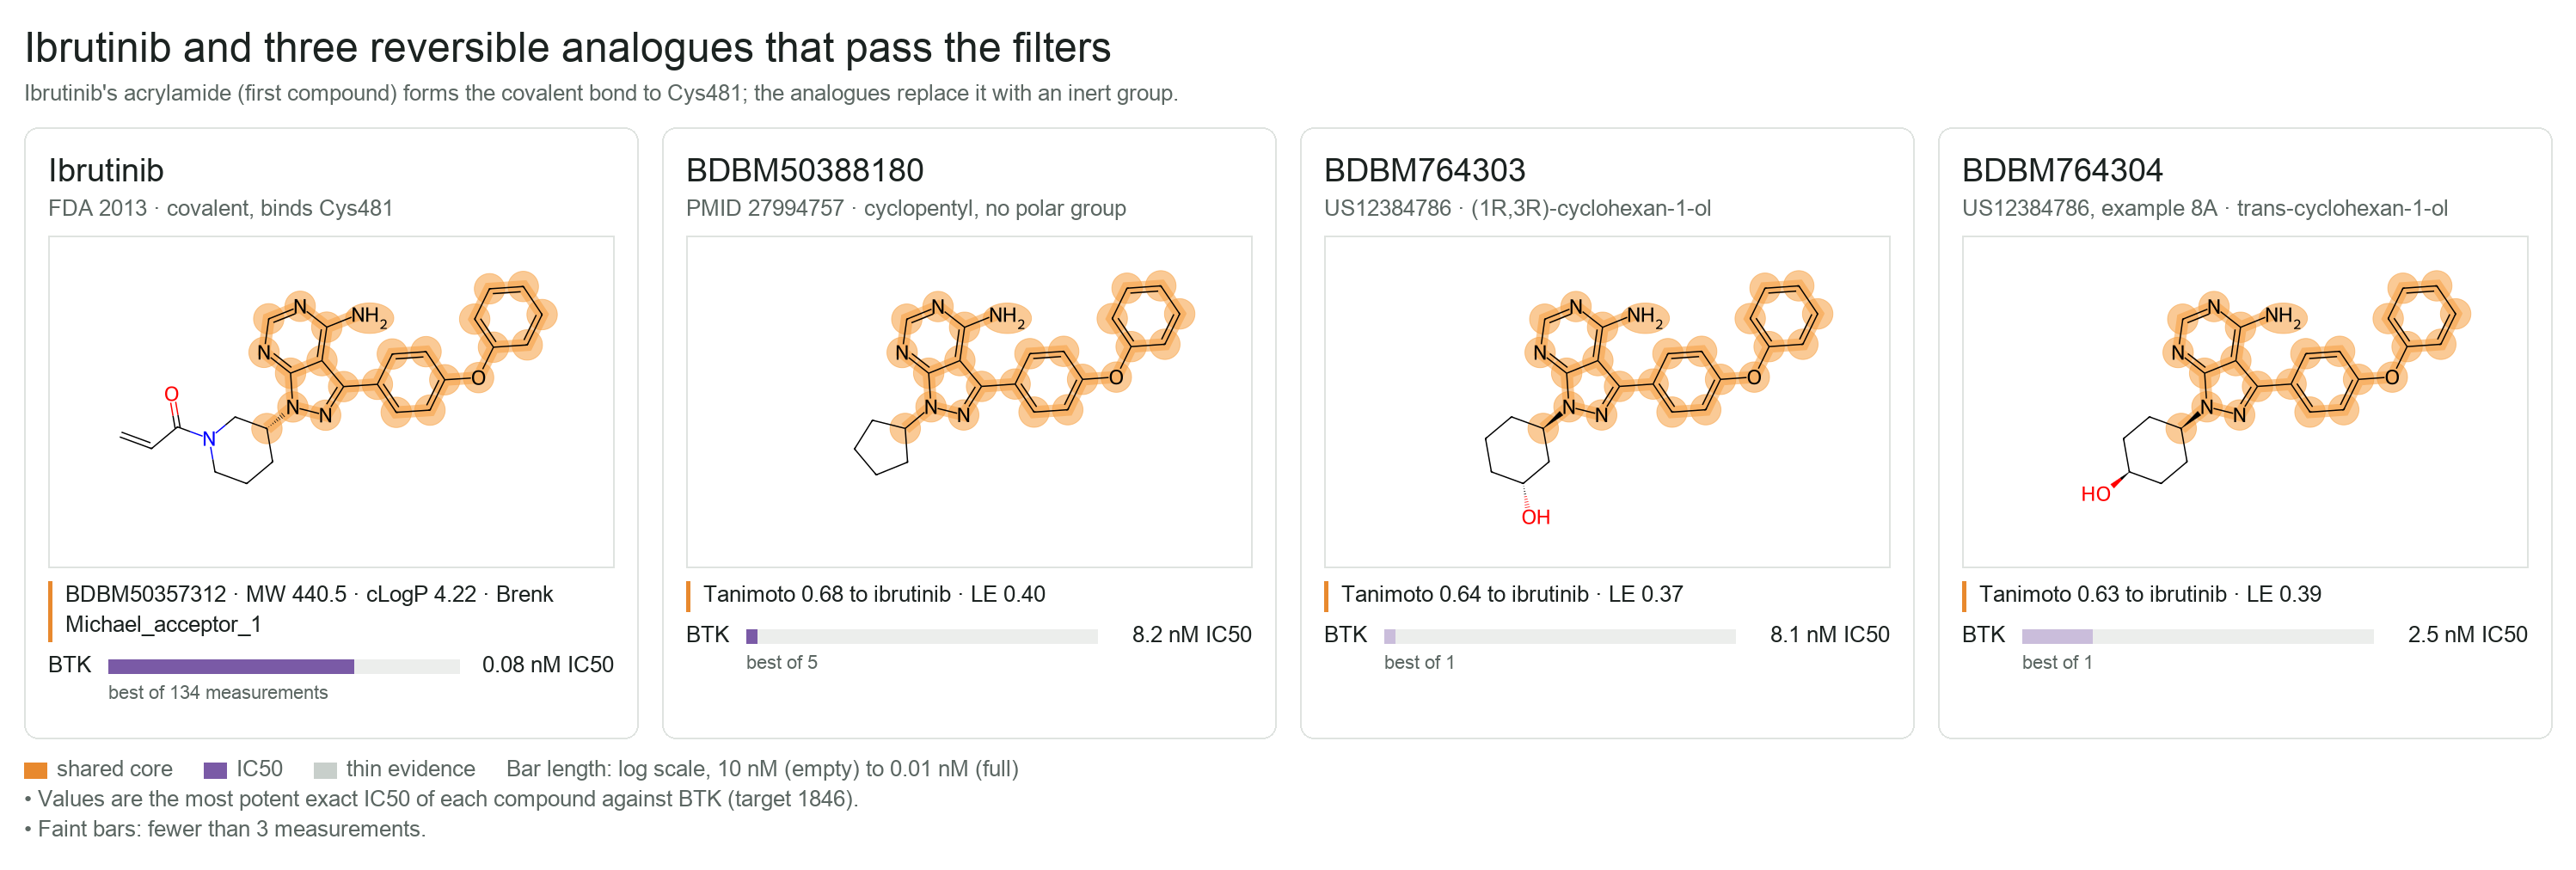

In [ ]:
# Figure 1 · draw_structure_grid draws it again
arguments = {
    'title': 'Ibrutinib and three reversible analogues that pass the filters',
    'compounds': [
        {
            'smiles': 'Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)[C@@H]1CCCN(C1)C(=O)C=C',
            'title': 'Ibrutinib',
            'subtitle': 'FDA 2013 · covalent, binds Cys481',
            'caption': 'BDBM50357312 · MW 440.5 · cLogP 4.22 · Brenk Michael_acceptor_1',
            'bars': [{'label': 'BTK', 'value_nm': 0.08, 'type': 'IC50', 'note': 'best of 134 measurements'}],
        },
        {
            'smiles': 'Nc1ncnc2n(nc(-c3ccc(Oc4ccccc4)cc3)c12)C1CCCC1',
            'title': 'BDBM50388180',
            'subtitle': 'PMID 27994757 · cyclopentyl, no polar group',
            'caption': 'Tanimoto 0.68 to ibrutinib · LE 0.40',
            'bars': [{'label': 'BTK', 'value_nm': 8.2, 'type': 'IC50', 'note': 'best of 5'}],
        },
        {
            'smiles': 'Nc1ncnc2c1c(-c1ccc(Oc3ccccc3)cc1)nn2[C@@H]1CCC[C@@H](O)C1',
            'title': 'BDBM764303',
            'subtitle': 'US12384786 · (1R,3R)-cyclohexan-1-ol',
            'caption': 'Tanimoto 0.64 to ibrutinib · LE 0.37',
            'bars': [{'label': 'BTK', 'value_nm': 8.1, 'type': 'IC50', 'note': 'best of 1', 'faint': True}],
        },
        {
            'smiles': 'Nc1ncnc2c1c(-c1ccc(Oc3ccccc3)cc1)nn2[C@H]1CC[C@@H](O)CC1',
            'title': 'BDBM764304',
            'subtitle': 'US12384786, example 8A · trans-cyclohexan-1-ol',
            'caption': 'Tanimoto 0.63 to ibrutinib · LE 0.39',
            'bars': [{'label': 'BTK', 'value_nm': 2.5, 'type': 'IC50', 'note': 'best of 1', 'faint': True}],
        },
    ],
    'columns': 4,
    'description': "Ibrutinib's acrylamide (first compound) forms the covalent bond to Cys481; the analogues replace it with an inert group.",
    'notes': [
        'Values are the most potent exact IC50 of each compound against BTK (target 1846).',
        'Faint bars: fewer than 3 measurements.',
    ],
    'min_core_atoms': 8,
    'min_core_share': 0.8,
}
await replay.figure(1, 'draw_structure_grid', arguments)

**🧠 Assistant**

Filtering works, but on this target the obvious filter set throws away the mechanism. Here is what each step removes.

| Search | Similar compounds with a BTK value ≤ 10 nM (similarity_search, Tanimoto ≥ 0.5) |
|---|---|
| none | 282 |
| + `max_mw: 450`, `exclude_alerts: ["pains"]` | 65 |
| + `exclude_alerts: ["pains", "brenk"]` | 5 |

**The first filter is cheap, the second is not.** Capping molecular weight at 450 and dropping PAINS matches cuts 282 analogues to 65, almost all of that from the weight cap, since only 89 of the 6,326 potent BTK compounds match any PAINS filter at all. Adding the Brenk filters cuts 65 to 5, and what it removes is the entire covalent series: 2,334 of those 6,326 compounds carry Michael_acceptor_1, and ibrutinib is one of them (the 282 and the 65 include ibrutinib itself). Its acrylamide is exactly what the filter is designed to catch, and exactly how the drug works: it forms a covalent bond to Cys481 in the BTK active site. The NIH filters flag the same group as acrylate (1,799 of the 6,326).

So for a covalent target, exclude PAINS but not Brenk, or you filter out the chemistry you came for. The reverse is also true: if you want *reversible* analogues, the Brenk filter is the fastest way to find them, which is what the five survivors are.

**The five that survive (Figure 1 shows ibrutinib and three of them)**

All five keep ibrutinib's 4-amino-pyrazolo[3,4-d]pyrimidine hinge binder and its aryl arm (phenoxyphenyl in four, a benzylphenyl in CHEMBL5197089, a fluorophenoxy-substituted one in BDBM764305), and replace the acrylamide-bearing piperidine with something inert: a plain cyclopentyl, a cyclohexanol, or a propanamide that cannot accept a Michael addition.

| Compound | Best BTK IC50 | Tanimoto | LE | Source |
|---|---|---|---|---|
| US12384786, example 8A (BDBM764304) | 2.5 nM | 0.63 | 0.39 | Patent |
| BDBM764305 | 3.8 nM | 0.54 | 0.37 | Patent |
| CHEMBL5197089 (BDBM50594228) | 4.7 nM | 0.61 | 0.35 | PMID 35594541 |
| BDBM764303 | 8.1 nM | 0.64 | 0.37 | Patent |
| CHEMBL2057912 (BDBM50388180) | 8.2 nM | 0.68 | 0.40 | PMID 27994757 and others |

They are all 2.5 to 8 nM, about 30 to 100 times weaker than ibrutinib's best reported 0.08 nM, but that comparison is unfair in a specific way. A covalent inhibitor's IC50 depends on how long the enzyme and compound are pre-incubated, because the covalent bond keeps forming; a reversible compound's does not. Comparing a reversible IC50 with a covalent IC50 measures the assay protocol as much as the compounds. Three of the five are single-measurement patent values.

In Figure 1 the four compounds are aligned on their largest common substructure, 24 atoms: the 4-amino-pyrazolo[3,4-d]pyrimidine hinge binder together with the phenoxyphenyl arm, highlighted as the shared core. Only the group at the pyrazole nitrogen differs.

**Caveats on the filters themselves**

- The weight cap is on the RDKit weight of the parent (salts and solvents removed), from compound_property, which is why it can differ from compound.mol_weight, BindingDB's weight for the whole record.
- exclude_alerts drops a compound if it matches *any* alert in the named catalog. The catalogs are unequal in temperament: PAINS has 480 patterns aimed at assay interference, Brenk has 105 aimed at reactive or unstable groups in a lead, and the NIH set overlaps both. Brenk fires on roughly 47% of BTK's potent compounds (2,957 of 6,326) and PAINS on 1.4%, so "exclude alerts" means something very different depending on which you pass.
- Similarity is Tanimoto on Morgan fingerprints (radius 2, 2048 bits) of the largest fragment, and 0.5 is a loose threshold: the five survivors run from 0.54 to 0.68.

**How this was answered**

- search_compounds found ibrutinib (BDBM50357312, 454 measurements) and search_targets found human BTK (target 1846; the C481S resistance mutant, target 502, is a separate target).
- get_compound read ibrutinib's own row in compound_property: MW 440.51, cLogP 4.22, QED 0.47, Brenk Michael_acceptor_1, NIH acrylate and halo_acrylate.
- similarity_search with threshold: 0.5, target_id: 1846 and max_value_nm: 10, run three times: unfiltered, then with properties: {max_mw: 450, exclude_alerts: ["pains"]}, then with brenk added. The property filter is applied before the result limit, so the counts are the real counts, not a filtered page.
- A run_sql query counted how many of BTK's potent compounds carry each alert class, and a second one read the best IC50 and sources of ibrutinib and the five survivors.
- draw_structure_grid drew ibrutinib with three of the survivors, aligned on their shared hinge binder and aryl arm.

**Try next**

- "Which of these five have been tested against the C481S mutant?" (find_targets_for_compound, or target 502)
- "Find reversible BTK inhibitors on a different scaffold" (the same filters on find_ligands_for_target with group_by_scaffold: true)
- Example 5.3 expands a hit without property filters, for comparison.

## Verification

How each rerun call compared with its recorded result.

In [ ]:
replay.summary()

_Recorded: 8 tool calls, 1 figure to redraw. Run all cells to compare._

## How to cite

Cite this notebook (for example deposited with a DOI) together with the data and software it ran on:

- Data: BindingDB release 202611, https://www.bindingdb.org/rwd/bind/BDB-mySQL_All_202611_dmp.zip (SHA-256 daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381)
- Software: mcp-bindingdb v0.1.17, commit 79dae5d22c0f15b8ded9b49adc8b105f0463703a, https://github.com/sbl-sdsc/mcp-bindingdb
- Analysis: Example 7.5 — Property-filtered analogue search: ibrutinib and BTK, 2026-11-23, with claude-sonnet-5-5
- BindingDB: Liu T, Hwang L, Burley SK, Nitsche CI, Southan C, Walters WP, Gilson MK. BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data. Nucleic Acids Research 53(D1):D1633-D1644, 2025. https://doi.org/10.1093/nar/gkae1075

As BibTeX, for this server, BindingDB and RDKit (used for structure search, properties and drawings):

```bibtex
@software{rose2026mcp-bindingdb,
  title={MCP BindingDB Server},
  author={Rose, P.W.},
  year={2026},
  url={https://github.com/sbl-sdsc/mcp-bindingdb}
}

@article{liu2025bindingdb,
  title={BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data},
  author={Liu, T. and Hwang, L. and Burley, S.K. and Nitsche, C.I. and Southan, C. and Walters, W.P. and Gilson, M.K.},
  journal={Nucleic Acids Research},
  volume={53},
  number={D1},
  pages={D1633--D1644},
  year={2025},
  doi={10.1093/nar/gkae1075}
}

@software{rdkit,
  title={RDKit: Open-source cheminformatics},
  author={Landrum, G. and others},
  version={2026.03.6},
  url={https://www.rdkit.org},
  doi={10.5281/zenodo.591637}
}
```